# Random-feature clustering analysis

## Step 1: a wider, balanced candidate pool

Build **50 candidate state features: 25 macro/market features and 25 technical features**. Store the S&P 500 daily log return separately and add it as a **mandatory eleventh clustering input** in every repetition. It is not part of the random 50-feature pool. The macro block consists of daily market-based macro-financial proxies, not daily observations of GDP, earnings or economic growth.

This notebook starts a separate experiment. It reads the existing equity history and eight technical indicators, downloads additional inputs, checks coverage and redundancy, applies selective logs and standard scaling, and saves the expanded dataset. The later sections run repeated balanced feature draws and compare five clustering approaches; results remain descriptive. Run from the repository folder using its `.venv` kernel. The fixed research window is inherited from `01`; this expansion does not refresh its end date.

The project continues to use the [Fortitudo EP/FFR framework](https://github.com/fortitudo-tech/pcrm-book). Random feature subsets would test the robustness of the learned partition before supplying its profiles to EP.

## What would the randomization establish?

For repetition $b$, sample a feature subset $S_b$ of size 10 and append the mandatory S&P 500 daily log return. Fit preprocessing on all 11 columns, denoted by $\widetilde S_b$. For silhouette-selected count models, select

$$\widehat K_b=\arg\max_{K\in\{2,\ldots,8\}}\operatorname{Silhouette}\bigl(X_{\widetilde S_b},\widehat c^{(b,K)}\bigr).$$

Here $X_{\widetilde S_b}$ denotes the scaled representation used for scoring; document any PCA truncation explicitly. Each repetition selects its own count rather than inheriting two clusters. GMM uses BIC within the draw; DBSCAN selects density settings, as specified below. The count is data-dependent **within the candidate range and the declared criterion**.

| Question | Evidence to report | What a positive result would support |
| --- | --- | --- |
| Is the selected count stable? | Frequency of every selected K; full candidate-score curves; gaps between first and second choices | Similar geometric resolution across the sampled feature sets |
| Are the same dates grouped together? | Pairwise adjusted Rand index (ARI), adjusted mutual information (AMI), and a date-by-date co-assignment matrix | Partition agreement beyond simply selecting the same K |
| Do similar state profiles recur? | Means, dispersion and population shares on the **same fixed profiling panel**, with cluster matching where appropriate | Similar empirical state descriptions despite changing the fitted inputs |
| Are smaller/stressed groups consistent? | Matched-state Jaccard overlap and cluster-level diagnostics, not just an overall agreement score | Stability beyond a large common calm group |
| Does the result survive new histories? | Rolling/expanding training windows and held-out assignments | Temporal robustness, which feature resampling alone cannot establish |
| Does it help EP? | Later held-out conditional return distributions, tail-risk calibration, posterior concentration and matched threshold benchmarks | Incremental usefulness of cluster-based EP views |

**A defensible claim, if supported:** the partition and its profiles are robust to the specified feature perturbations within this candidate universe and historical sample. It would not prove a true or unique economic regime count, economic causality, superior forecasts, or superiority to manual partitioning.

Importantly, drawing 10 out of 50 tests **robustness across 11-dimensional views: ten sampled features plus a fixed equity-return anchor**. It does not directly demonstrate successful clustering in the full candidate pool plus the equity-return anchor. Add a full-pool benchmark and, later, sampled subset sizes such as 5, 10, 20 and 50, each with the fixed equity-return anchor to investigate that separate claim. Fifty columns also do not imply fifty independent information sources.

Related foundations: [von Luxburg, clustering stability](https://arxiv.org/abs/1007.1075), [Strehl and Ghosh, cluster ensembles](https://jmlr.org/papers/v3/strehl02a.html), and [ARI documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html). We are proposing a robustness experiment here, not claiming a new clustering algorithm.

## Candidate balance and source choices

| Block | Family | Features |
| --- | --- | ---: |
| Macro/market | Rates and policy | 6 |
| Macro/market | Inflation compensation and real yields | 4 |
| Macro/market | Credit and short-end Treasury curve | 5 |
| Macro/market | FX and commodities | 6 |
| Macro/market | Implied volatility | 4 |
| Technical | Trend and momentum | 6 |
| Technical | Drawdown and path efficiency | 3 |
| Technical | Realized risk and distribution shape | 6 |
| Technical | Oscillators and trading ranges | 5 |
| Technical | Relative market performance | 5 |

This is a starting pool, not a list of 50 validated predictors. Related maturities and overlapping technical windows can reproduce the same latent stress factor. Equal column counts balance the two blocks numerically, not their economic information. Family-stratified draws and leave-one-family-out checks will address that sensitivity.

Daily additions use FRED Treasury, inflation, currency and oil series; Cboe VVIX; and adjusted ETF prices for relative performance. The existing Baa spread remains and an Aaa spread is added. The 3-month minus 4-week T-bill spread describes the short end of the Treasury curve on a common discount basis; it is not a corporate funding or liquidity spread. HYG/IEF is a relative ETF-performance proxy, not an option-adjusted credit spread; duration and distributions also affect it.

**Availability constraint:** [FRED's ICE high-yield OAS notes](https://fred.stlouisfed.org/series/BAMLH0A0HYM2) state that only three years of observations are supplied from April 2026. It is excluded from this 15-year daily experiment. SOFR also does not cover the full window. Observed commercial-paper coverage was also poor: the 90-day AA financial CP series covered 82.10% of the original equity dates and its 21-row spread change only 71.59%; the 30-day alternative covered 62.86%. The initial CP-based pool retained just 2,629 dates, including only 20.2% of equity dates in 2024. Both CP candidates were rejected on coverage grounds before clustering; the final pool uses the better-covered short-end Treasury slope and its change instead. This is a different economic proxy, not a substitute credit spread.

Monthly earnings, CPI and unemployment remain candidates for a separate release-date-aligned extension; repeating monthly values on daily rows would not add daily observations of the underlying economy.

All raw inputs and exports stay in ignored `data/`. These are currently available histories, not point-in-time vintages. Same-date joins below are descriptive: publication delays, differing close times and historical revisions still need explicit treatment before forecasting. S&P-derived state descriptors also require alignment to **subsequent** returns for a predictive state--outcome design.

In [1]:
from pathlib import Path
from io import StringIO
import json

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_palette("colorblind")
DATA_DIR = Path("data/random_features")
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
yf.set_tz_cache_location(str(DATA_DIR / "yfinance_cache"))

metadata = json.loads(Path("data/metadata.json").read_text())
START = pd.Timestamp(metadata["requested_start"])
END = pd.Timestamp(metadata["requested_end"])
AS_OF = pd.Timestamp(metadata["as_of_exclusive"])

## Load the existing data

Keep the full equity calendar during feature construction. A 21-day change below means 21 **equity trading rows**, before complete-case filtering. No forward-fill or interpolation is used; a missing input at either endpoint leaves a missing change. Technical rolling windows use the buffered equity history from `01`.

In [2]:
levels = pd.read_csv("data/daily_macro_levels.csv", index_col="date", parse_dates=["date"])
equity = pd.read_csv("data/raw/yahoo_sp500.csv", index_col="date", parse_dates=["date"])
equity = equity.sort_index()
calendar = equity.index
DOWNLOAD_START = calendar.min()
close = equity["Close"]
returns = np.log(close).diff()
levels.head()

Out[2]: 
                  sp500  breakeven_10y  ...  sp500_ma_gap_200d  sp500_atrp_14d
date                                    ...                                   
2011-10-05  1144.030029           1.80  ...          -0.105030        2.877053
2011-10-06  1164.969971           1.88  ...          -0.088329        2.811149
2011-10-07  1155.459961           1.94  ...          -0.095405        2.762521
2011-10-10  1194.890015            NaN  ...          -0.064309        2.716376
2011-10-11  1195.540039           1.95  ...          -0.063573        2.592314

[5 rows x 17 columns]


## Download the additional daily inputs

Cache each source locally so rerunning analysis does not repeatedly download it. To refresh this experiment, remove only its cached source files and rerun; cached files otherwise preserve the download used here. The requests cover the original window plus the existing equity warmup. Source URLs and retrieval times are saved alongside the raw files.

FRED identifiers below identify the source series; the construction cells specify every transformation. Cboe's [VVIX](https://www.cboe.com/us/indices/dashboard/vvix/) measures implied volatility of VIX, a different quantity from equity-return volatility. Yahoo ETF closes use `auto_adjust=True`, incorporating the provider's split/distribution adjustments; gold uses a futures-price proxy and may include roll effects.

In [3]:
fred_ids = {
    "policy_rate": "DFF", "tbill_3m": "DTB3", "nominal_yield_30y": "DGS30",
    "slope_10y_2y": "T10Y2Y", "real_yield_5y": "DFII5", "real_yield_10y": "DFII10",
    "breakeven_5y": "T5YIE", "breakeven_10y": "T10YIE",
    "baa_10y_spread": "BAA10Y", "aaa_10y_spread": "AAA10Y", "tbill_4wk": "DTB4WK",
    "broad_usd": "DTWEXBGS", "eurusd": "DEXUSEU", "usdjpy": "DEXJPUS",
    "wti": "DCOILWTICO",
}

fred_series = {}
for name, series_id in fred_ids.items():
    path = RAW_DIR / f"fred_{series_id}.csv"
    if not path.exists():
        response = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv", params={
            "id": series_id, "cosd": DOWNLOAD_START.strftime("%Y-%m-%d"),
            "coed": END.strftime("%Y-%m-%d"),
        }, timeout=60)
        response.raise_for_status()
        table = pd.read_csv(StringIO(response.text), na_values=["."])
        assert series_id in table.columns, f"FRED response is missing {series_id}"
        path.write_text(response.text)
        (RAW_DIR / f"fred_{series_id}_source.json").write_text(json.dumps({
            "url": response.url, "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        }, indent=2))
    table = pd.read_csv(path, index_col=0, parse_dates=True, na_values=["."])
    fred_series[name] = table[series_id].rename(name)

fred = pd.concat(fred_series.values(), axis=1).reindex(calendar)
fred.head()

Out[3]: 
            policy_rate  tbill_3m  nominal_yield_30y  ...  eurusd  usdjpy    wti
date                                                  ...                       
2009-10-05         0.13      0.08               4.01  ...  1.4647   89.56  70.26
2009-10-06         0.12      0.08               4.07  ...  1.4744   88.77  70.71
2009-10-07         0.13      0.09               3.99  ...  1.4675   88.76  69.60
2009-10-08         0.12      0.06               4.09  ...  1.4777   88.44  71.69
2009-10-09         0.12      0.07               4.22  ...  1.4715   89.69  71.75

[5 rows x 15 columns]


In [4]:
vvix_path = RAW_DIR / "cboe_VVIX.csv"
if not vvix_path.exists():
    url = "https://cdn.cboe.com/api/global/us_indices/daily_prices/VVIX_History.csv"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    vvix_path.write_text(response.text)
    (RAW_DIR / "vvix_source.json").write_text(json.dumps({
        "url": url, "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    }, indent=2))

vvix = pd.read_csv(vvix_path)
vvix.columns = vvix.columns.str.strip().str.upper()
vvix = pd.Series(pd.to_numeric(vvix["VVIX"], errors="coerce").to_numpy(),
                 index=pd.to_datetime(vvix["DATE"], format="%m/%d/%Y"), name="vvix")

tickers = ["SPY", "IWM", "QQQ", "IWF", "IWD", "XLY", "XLP", "HYG", "IEF", "GC=F"]
prices_path = RAW_DIR / "adjusted_market_closes.csv"
if not prices_path.exists():
    market = yf.download(tickers, start=DOWNLOAD_START.strftime("%Y-%m-%d"),
                         end=AS_OF.strftime("%Y-%m-%d"), auto_adjust=True,
                         progress=False, threads=False, timeout=30)["Close"]
    market.index = pd.DatetimeIndex(market.index).tz_localize(None).normalize()
    assert set(tickers).issubset(market.columns), "Some Yahoo tickers were not returned"
    assert market[tickers].notna().any().all(), "A Yahoo ticker has no observations"
    market.to_csv(prices_path, index_label="date")
    (RAW_DIR / "market_source.json").write_text(json.dumps({
        "tickers": tickers, "auto_adjust": True,
        "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    }, indent=2))

market = pd.read_csv(prices_path, index_col="date", parse_dates=["date"]).reindex(calendar)
market.head()

Out[4]: 
                   GC=F        HYG        IEF  ...        SPY        XLP        XLY
date                                           ...                                 
2009-10-05  1016.700012  31.512024  62.404491  ...  77.023415  16.038443  10.947089
2009-10-06  1038.599976  31.403934  62.202671  ...  78.126717  16.183846  11.113689
2009-10-07  1043.300049  31.635033  62.599628  ...  78.341476  16.253389  11.121817
2009-10-08  1055.400024  31.836327  62.370850  ...  78.941238  16.348219  11.300611
2009-10-09  1047.800049  31.959311  61.772152  ...  79.422562  16.386150  11.296548

[5 rows x 10 columns]


## Construct 25 macro/market features

Keep rates and spreads in published percent or percentage-point units. Changes in rates are **differences**, not log returns; `yield_change_21d` refers to the 30-year nominal yield. FX and gold momentum use 21-row log returns; USD strength has different signs in EURUSD and USDJPY, as documented in the catalogue. WTI uses its dollar level and a dollar change, allowing non-positive observations without taking their logarithm.

Retain VIX and VIX minus VIX3M, but exclude the VIX3M level from this pool to avoid the exact three-column identity present in `02`. The nominal yield uses 30 years, avoiding the additional exact 10-year identity `nominal yield = real yield + breakeven` in the same feature pool. Other correlated information remains.

In [5]:
macro_features = fred[[
    "policy_rate", "tbill_3m", "nominal_yield_30y", "slope_10y_2y",
    "real_yield_5y", "real_yield_10y", "breakeven_5y", "breakeven_10y",
    "baa_10y_spread", "aaa_10y_spread",
]].copy()
macro_features["yield_change_21d"] = fred["nominal_yield_30y"].diff(21)
macro_features["slope_change_21d"] = fred["slope_10y_2y"].diff(21)
macro_features["tbill_3m_4wk_spread"] = fred["tbill_3m"] - fred["tbill_4wk"]
macro_features["baa_spread_change_21d"] = fred["baa_10y_spread"].diff(21)
macro_features["bill_spread_change_21d"] = macro_features["tbill_3m_4wk_spread"].diff(21)

for name in ["broad_usd", "eurusd", "usdjpy"]:
    macro_features[name + "_momentum_21d"] = np.log(fred[name]).diff(21)
macro_features["gold_momentum_21d"] = np.log(market["GC=F"]).diff(21)
macro_features["wti"] = fred["wti"]
macro_features["wti_change_21d"] = fred["wti"].diff(21)

vix_history = pd.read_csv("data/raw/cboe_VIX.csv")
vix = pd.Series(vix_history["CLOSE"].to_numpy(),
                index=pd.to_datetime(vix_history["DATE"], format="%m/%d/%Y")).reindex(calendar)
macro_features["vix"] = vix
macro_features["vix_term_spread"] = levels["vix_term_spread"].reindex(calendar)
macro_features["vvix"] = vvix.reindex(calendar)
macro_features["vix_change_21d"] = vix.diff(21)
macro_features.shape

Out[5]: (4275, 25)


## Construct 25 technical features

Reuse the eight existing indicators unchanged. Add further horizons and distribution/range descriptors on the full equity calendar. Realized volatility uses population standard deviation and 252-day annualization. Downside volatility is explicitly `sqrt(mean(min(r, 0)^2)) * sqrt(252) * 100`, not volatility of only the negative-return subsample. Skewness and excess kurtosis use pandas' rolling sample estimators.

Close location is `(Close - Low) / (High - Low)`, missing when the range is zero; up-day share is the fraction of positive daily log returns over 21 rows; range is `100 * (High - Low) / Close`. These are provider OHLC and trailing path descriptors. All values include today's observation and are available only after the relevant inputs are published.

The five relative features are 21-row log changes of adjusted-price ratios: small/large caps (`IWM/SPY`), Nasdaq/large caps (`QQQ/SPY`), growth/value (`IWF/IWD`), discretionary/staples (`XLY/XLP`), and high-yield/Treasury ETFs (`HYG/IEF`). They are interpretable proxies with overlapping exposures, not pure economic factors.

In [6]:
existing_technicals = [
    "sp500_momentum_63d", "sp500_drawdown_252d", "sp500_realized_vol_21d",
    "sp500_volatility_expansion_21_126d", "sp500_trend_efficiency_21d",
    "sp500_rsi_14d", "sp500_ma_gap_200d", "sp500_atrp_14d",
]
technical_features = levels[existing_technicals].reindex(calendar).copy()

for window in [21, 126, 252]:
    technical_features[f"sp500_momentum_{window}d"] = np.log(close).diff(window)
technical_features["sp500_drawdown_63d"] = close / close.rolling(63).max() - 1
technical_features["sp500_realized_vol_63d"] = returns.rolling(63).std(ddof=0) * np.sqrt(252) * 100
technical_features["sp500_downside_vol_21d"] = np.sqrt(
    returns.clip(upper=0).pow(2).rolling(21).mean()) * np.sqrt(252) * 100
technical_features["sp500_skew_63d"] = returns.rolling(63).skew()
technical_features["sp500_excess_kurtosis_126d"] = returns.rolling(126).kurt()
technical_features["sp500_ma_gap_50d"] = close / close.rolling(50).mean() - 1
technical_features["sp500_close_location"] = (close - equity["Low"]) / (equity["High"] - equity["Low"]).replace(0, np.nan)
technical_features["sp500_up_day_share_21d"] = returns.gt(0).where(returns.notna()).rolling(21).mean()
technical_features["sp500_range_pct"] = 100 * (equity["High"] - equity["Low"]) / close

relative_pairs = {
    "small_large_momentum_21d": ("IWM", "SPY"),
    "nasdaq_sp500_momentum_21d": ("QQQ", "SPY"),
    "growth_value_momentum_21d": ("IWF", "IWD"),
    "cyclical_defensive_momentum_21d": ("XLY", "XLP"),
    "hy_treasury_momentum_21d": ("HYG", "IEF"),
}
for name, (numerator, denominator) in relative_pairs.items():
    technical_features[name] = np.log(market[numerator] / market[denominator]).diff(21)
technical_features.shape

Out[6]: (4275, 25)


## Feature families

Keep a catalogue so randomization can respect blocks or families without relying on column position. The existing S&P/gold level ratio is not carried into this pool; gold momentum supplies a cross-market alternative. This is a separately defined experiment, not an unchanged 17-feature baseline with extra columns.

In [7]:
families = {
    "rates_policy": ["policy_rate", "tbill_3m", "nominal_yield_30y", "slope_10y_2y",
                     "yield_change_21d", "slope_change_21d"],
    "inflation_real_rates": ["breakeven_5y", "breakeven_10y", "real_yield_5y", "real_yield_10y"],
    "credit_short_end": ["baa_10y_spread", "aaa_10y_spread", "tbill_3m_4wk_spread",
                       "baa_spread_change_21d", "bill_spread_change_21d"],
    "fx_commodities": ["broad_usd_momentum_21d", "eurusd_momentum_21d", "usdjpy_momentum_21d",
                       "gold_momentum_21d", "wti", "wti_change_21d"],
    "implied_volatility": ["vix", "vix_term_spread", "vvix", "vix_change_21d"],
    "trend_momentum": ["sp500_momentum_21d", "sp500_momentum_63d", "sp500_momentum_126d",
                       "sp500_momentum_252d", "sp500_ma_gap_50d", "sp500_ma_gap_200d"],
    "drawdown_path": ["sp500_drawdown_63d", "sp500_drawdown_252d", "sp500_trend_efficiency_21d"],
    "realized_risk": ["sp500_realized_vol_21d", "sp500_realized_vol_63d",
                      "sp500_volatility_expansion_21_126d", "sp500_downside_vol_21d",
                      "sp500_skew_63d", "sp500_excess_kurtosis_126d"],
    "oscillators_ranges": ["sp500_rsi_14d", "sp500_atrp_14d", "sp500_close_location",
                           "sp500_up_day_share_21d", "sp500_range_pct"],
    "relative_markets": list(relative_pairs),
}
macro_families = list(families)[:5]
feature_catalog = pd.DataFrame([
    {"feature": feature, "block": "macro_market" if family in macro_families else "technical",
     "family": family}
    for family, features in families.items() for feature in features
]).set_index("feature")
display(feature_catalog.groupby(["block", "family"], sort=False).size().rename("features"))
feature_catalog

Out[7]: 
                                           block                family
feature                                                               
policy_rate                         macro_market          rates_policy
tbill_3m                            macro_market          rates_policy
nominal_yield_30y                   macro_market          rates_policy
slope_10y_2y                        macro_market          rates_policy
yield_change_21d                    macro_market          rates_policy
slope_change_21d                    macro_market          rates_policy
breakeven_5y                        macro_market  inflation_real_rates
breakeven_10y                       macro_market  inflation_real_rates
real_yield_5y                       macro_market  inflation_real_rates
real_yield_10y                      macro_market  inflation_real_rates
baa_10y_spread                      macro_market      credit_short_end
aaa_10y_spread                      macro_market      credit_short_e

block         family              
macro_market  rates_policy            6
              inflation_real_rates    4
              credit_short_end        5
              fx_commodities          6
              implied_volatility      4
technical     trend_momentum          6
              drawdown_path           3
              realized_risk           6
              oscillators_ranges      5
              relative_markets        5
Name: features, dtype: int64

## Align, inspect missing values and preview

`feature_pool` preserves all equity dates in the original window. `X_complete` uses **one common complete-case calendar across all 50 features**, so later feature-subset comparisons will hold dates fixed. This sacrifices some data; the coverage tables make the cost visible. Do not drop different rows independently within each random draw. A poor-coverage series should trigger a documented pool revision rather than silently shrinking every comparison.

`outcomes` contains contemporaneous daily S&P 500 price-index log and simple returns (excluding dividends), calculated before any filtering. It is saved separately and excluded from `feature_catalog` and the randomization pool; its log-return column is joined as a fixed input in every clustering fit below. Predictive testing will require separate forward-return alignment, including overlap-aware evaluation at multi-day horizons.

In [8]:
feature_pool = pd.concat([macro_features, technical_features], axis=1).loc[START:END]
feature_pool = feature_pool[feature_catalog.index].replace([np.inf, -np.inf], np.nan)
feature_pool.index.name = "date"
X_complete = feature_pool.dropna().copy()

outcomes = pd.DataFrame({"sp500_log_return": returns, "sp500_simple_return": np.expm1(returns)})
outcomes = outcomes.reindex(feature_pool.index)

assert feature_pool.shape[1] == 50 and feature_pool.columns.is_unique
assert len(macro_features.columns) == len(technical_features.columns) == 25
assert feature_pool.index.is_unique and feature_pool.index.is_monotonic_increasing
assert not X_complete.empty and np.isfinite(X_complete.to_numpy()).all()
assert X_complete.nunique().gt(1).all()
assert "sp500_log_return" not in feature_pool.columns
assert outcomes.loc[X_complete.index].notna().all().all()

quality = feature_catalog.join(pd.DataFrame({
    "missing_rows": feature_pool.isna().sum(),
    "coverage_pct": 100 * feature_pool.notna().mean(),
    "first_observed": feature_pool.apply(lambda column: column.first_valid_index()),
    "last_observed": feature_pool.apply(lambda column: column.last_valid_index()),
}))
display(pd.Series({
    "candidate_features": feature_pool.shape[1], "equity_dates": len(feature_pool),
    "common_complete_dates": len(X_complete),
    "retained_dates_pct": round(100 * len(X_complete) / len(feature_pool), 2),
    "first_complete": X_complete.index.min(), "last_complete": X_complete.index.max(),
}))
display(quality.sort_values("coverage_pct"))
X_complete.head()

Out[8]: 
            policy_rate  ...  hy_treasury_momentum_21d
date                     ...                          
2011-10-05         0.07  ...                 -0.043907
2011-10-06         0.07  ...                 -0.031798
2011-10-07         0.07  ...                 -0.023992
2011-10-11         0.07  ...                  0.012927
2011-10-12         0.07  ...                  0.028774

[5 rows x 50 columns]


candidate_features                        50
equity_dates                            3770
common_complete_dates                   3630
retained_dates_pct                     96.29
first_complete           2011-10-05 00:00:00
last_complete            2026-10-02 00:00:00
dtype: object

,block,family,missing_rows,coverage_pct,first_observed,last_observed
feature,,,,,,
broad_usd_momentum_21d,macro_market,fx_commodities,101,97.320955,2011-10-05,2026-10-02
usdjpy_momentum_21d,macro_market,fx_commodities,76,97.984085,2011-10-05,2026-10-02
eurusd_momentum_21d,macro_market,fx_commodities,76,97.984085,2011-10-05,2026-10-02
baa_spread_change_21d,macro_market,credit_short_end,58,98.461538,2011-10-05,2026-10-02
yield_change_21d,macro_market,rates_policy,54,98.567639,2011-10-05,2026-10-02
slope_change_21d,macro_market,rates_policy,54,98.567639,2011-10-05,2026-10-02
wti_change_21d,macro_market,fx_commodities,54,98.567639,2011-10-05,2026-10-02
bill_spread_change_21d,macro_market,credit_short_end,54,98.567639,2011-10-05,2026-10-02
baa_10y_spread,macro_market,credit_short_end,30,99.204244,2011-10-05,2026-10-02


In [9]:
coverage_by_year = pd.DataFrame({
    "equity_dates": feature_pool.groupby(feature_pool.index.year).size(),
    "complete_dates": X_complete.groupby(X_complete.index.year).size(),
}).fillna(0).astype(int)
coverage_by_year["retained_pct"] = 100 * coverage_by_year["complete_dates"] / coverage_by_year["equity_dates"]
coverage_by_year.round(1)

Out[9]: 
      equity_dates  complete_dates  retained_pct
date                                            
2011            61              57          93.4
2012           250             246          98.4
2013           252             242          96.0
2014           252             234          92.9
2015           252             227          90.1
2016           252             242          96.0
2017           251             243          96.8
2018           251             237          94.4
2019           252             239          94.8
2020           253             245          96.8
2021           252             242          96.0
2022           251             246          98.0
2023           250             246          98.4
2024           252             248          98.4
2025           250             247          98.8
2026           189             189         100.0


## Redundancy check

Inspect highly correlated pairs before treating stable results as broad-based evidence. Correlation is not a complete test of redundancy, and this is an exploratory full-sample diagnostic. Similar indicators can make agreement look strong because repeated draws recover the same underlying factor. Freeze any feature pruning using training data before a held-out study.

In [10]:
correlation = X_complete.corr()
upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
correlated_pairs = upper.stack().rename("correlation").reset_index()
correlated_pairs.columns = ["feature_1", "feature_2", "correlation"]
correlated_pairs = correlated_pairs.loc[correlated_pairs["correlation"].abs().ge(0.90)]
correlated_pairs = correlated_pairs.sort_values("correlation", key=abs, ascending=False)
correlated_pairs

Out[10]: 
                   feature_1               feature_2  correlation
0                policy_rate                tbill_3m     0.996310
364            real_yield_5y          real_yield_10y     0.969617
1107  sp500_realized_vol_21d  sp500_downside_vol_21d     0.961301
1111  sp500_realized_vol_21d          sp500_atrp_14d     0.954230
1150  sp500_downside_vol_21d          sp500_atrp_14d     0.929575
279             breakeven_5y           breakeven_10y     0.928939
445           baa_10y_spread          aaa_10y_spread     0.903917
103        nominal_yield_30y          real_yield_10y     0.902637


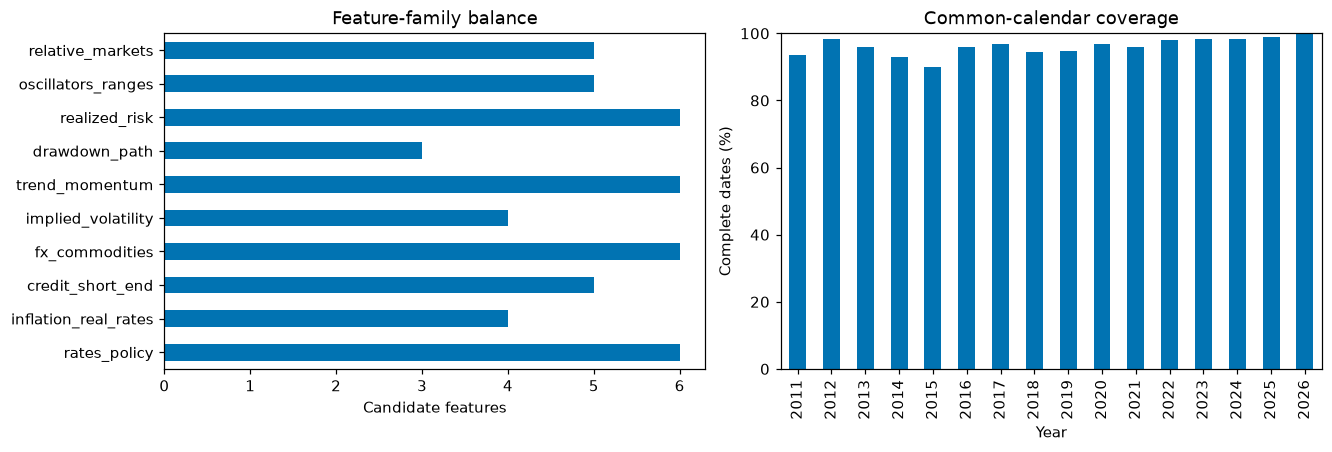

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
feature_catalog.groupby("family", sort=False).size().plot.barh(ax=axes[0])
axes[0].set(xlabel="Candidate features", ylabel="", title="Feature-family balance")
coverage_by_year["retained_pct"].plot.bar(ax=axes[1])
axes[1].set(xlabel="Year", ylabel="Complete dates (%)", ylim=(0, 100), title="Common-calendar coverage")
plt.show()

## Log transformation and StandardScaler

Apply natural logs to the seven selected positive volatility/range features, then standardize all 50 features. `X_complete` stays in original units for profiles; `df_transformed` contains the selective logs; `subset_scaled_df` is the standardized clustering input.

This follows the direct scaling steps in the MIT fantasy-sports reference notebook. Scaling here uses the full sample for descriptive analysis. For chronological validation, fit the scaler on training dates only.

In [12]:
log_columns = [
    "vix", "vvix", "sp500_realized_vol_21d", "sp500_realized_vol_63d",
    "sp500_downside_vol_21d", "sp500_atrp_14d", "sp500_range_pct",
]

df_transformed = X_complete.copy()
df_transformed[log_columns] = np.log(df_transformed[log_columns])
df_transformed.head()

Out[12]: 
            policy_rate  ...  hy_treasury_momentum_21d
date                     ...                          
2011-10-05         0.07  ...                 -0.043907
2011-10-06         0.07  ...                 -0.031798
2011-10-07         0.07  ...                 -0.023992
2011-10-11         0.07  ...                  0.012927
2011-10-12         0.07  ...                  0.028774

[5 rows x 50 columns]


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
subset = df_transformed.copy()
subset_scaled = scaler.fit_transform(subset)

In [14]:
subset_scaled_df = pd.DataFrame(
    subset_scaled, columns=subset.columns, index=subset.index
)
subset_scaled_df.head()

Out[14]: 
            policy_rate  ...  hy_treasury_momentum_21d
date                     ...                          
2011-10-05    -0.867462  ...                 -1.830186
2011-10-06    -0.867462  ...                 -1.358912
2011-10-07    -0.867462  ...                 -1.055130
2011-10-11    -0.867462  ...                  0.381655
2011-10-12    -0.867462  ...                  0.998378

[5 rows x 50 columns]


## Save this experiment separately

The first export preserves missing values; the second is the common complete-case feature matrix. Separate log-transformed and standardized exports are also saved. The catalogue, quality table, yearly coverage and source records keep the pool auditable. Source data remain local under their providers' terms. The 17-feature datasets used in `01` and `02` are unchanged.

In [15]:
feature_pool.to_csv(DATA_DIR / "feature_pool_50.csv")
X_complete.to_csv(DATA_DIR / "feature_pool_50_complete.csv")
df_transformed.to_csv(DATA_DIR / "feature_pool_50_log.csv")
subset_scaled_df.to_csv(DATA_DIR / "feature_pool_50_scaled.csv")
outcomes.to_csv(DATA_DIR / "sp500_outcomes.csv")
feature_catalog.to_csv(DATA_DIR / "feature_catalog.csv")
quality.to_csv(DATA_DIR / "feature_quality.csv")
coverage_by_year.to_csv(DATA_DIR / "coverage_by_year.csv", index_label="year")

experiment_metadata = {
    "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "start": str(START.date()), "end": str(END.date()),
    "feature_count": len(feature_catalog), "families": families,
    "log_columns": log_columns,
    "scaling": "StandardScaler fitted on the full complete-case sample; descriptive analysis",
    "rows_all": len(feature_pool), "rows_complete": len(X_complete),
    "missing_policy": "no filling; fixed all-feature complete-case dates for random-subset comparisons",
    "source_histories": "currently available, not point-in-time vintages",
    "target_excluded_from_pool": True,
    "equity_return_in_modelling": "sp500_log_return is a fixed eleventh input, outside the random candidate pool", "fred_ids": fred_ids,
    "yahoo_tickers": tickers, "relative_pairs": relative_pairs,
    "original_metadata": metadata,
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__},
}
(DATA_DIR / "metadata.json").write_text(json.dumps(experiment_metadata, indent=2))
print(f"Saved {len(feature_catalog)} features and {len(X_complete):,} complete dates to {DATA_DIR}")

Saved 50 features and 3,630 complete dates to data/random_features


## Experiment design and wider validation plan

1. **Freeze the pool, calendar and recipe before viewing the winning draws.** Plan 200 draws per scheme for a larger study; the initial executed configuration below uses 50 balanced draws, a recorded feature-sampling seed, and all candidate scores retained. Report the distribution of results rather than the most attractive subset. Monte Carlo repetitions share observations and often features; they are not independent economic samples or confidence intervals for a true K.
2. **Primary draws: five macro/market plus five technical features and the fixed S&P return**, without replacement within each draw. Compare with unrestricted 10-of-50 draws. As a family-balance sensitivity, draw one feature from each of the ten families; its per-feature inclusion probabilities differ because families have different sizes. Audit feature/family inclusion frequencies and subset overlaps.
3. **Refit preprocessing on each selected subset.** Apply the same seven-feature log rule to any selected members of `log_columns`, then use StandardScaler and all eleven scaled dimensions, including the fixed equity return, to isolate feature sensitivity. If testing a PCA cutoff, fit PCA only on that draw's training columns and reselect the dimension there. PCA fitted to the full candidate pool would allow omitted features to influence the experiment. Compare robust scaling in a separate configuration, with count selection repeated there.
4. **Search models independently in every repetition.** For K=2–8, use silhouette for K-means, K-medoids and Ward, and BIC for converged GMM fits. K-means uses `n_init=20`; DBSCAN searches density settings instead of a specified K. A count of two at the lower boundary and a modest silhouette still need scrutiny. Silhouette cannot test K=1; use a gap/null-reference comparison to assess whether discrete groups are compelling at all. Fix the initialization recipe for feature-sensitivity comparisons, then run separate seed checks on identical subsets.
5. **Compare partitions on identical dates using ARI/AMI and co-assignment frequencies.** Numeric cluster labels have no fixed meaning. Equal K does not imply matching memberships. For equal-K profile comparisons, match groups through overlap or a fixed profile panel; when K differs, show splits/merges and unmatched groups rather than force one-to-one correspondence.
6. **Profile every fit on the same predeclared panel in original units**, including variables omitted from that draw. Record means, variances, quantiles, population shares and uncertainty; do not compare centroids from different PCA bases directly. Omitted descriptors from a correlated family are not independent validation. Analyze held-out forward S&P return distributions separately from this descriptive profiling.
7. **Challenge apparent stability.** Use family ablations, less-redundant pools and serial-dependence-aware surrogate controls (for example, independently circular-shift entire feature families to preserve their internal paths while disrupting cross-family alignment). Label these controls precisely: none supplies a universal no-regime null. Stability may reflect a dominant volatility factor or a continuous trend rather than discrete economic regimes.
8. **Separate feature robustness from temporal and EP validation.** Repeat with chronological training/test windows and appropriate gaps for overlapping forward returns. Compare the full 50-feature fit and varying subset sizes. Only after that, compare learned-profile EP against threshold views under matched dates, priors, constraints and resampling settings.

The balanced 5+5 implementation follows below. The other sampling schemes and forward-validation steps remain extensions.

## Repeated balanced modelling

Each repetition draws **five macro/market and five technical features without replacement**, adds **S&P 500 daily log return as a mandatory eleventh input**, refits log/StandardScaler preparation, and runs all five approaches on the same 3,630 dates. Different repetitions may reuse features. The feature seed controls the draws; the model seed is fixed to separate feature sensitivity from initialization sensitivity.

The first run uses **50 repetitions**; increase `N_REPEATS` for a larger Monte Carlo study, with candidate counts 2–8. `PCA_VARIANCE = None` keeps all eleven standardized inputs; set a fraction such as `0.70` to fit PCA separately within each draw. Geometry scores always use that draw's eleven standardized inputs, even if the fitted model uses truncated PCA scores. This is a full-sample descriptive experiment, not a forecast backtest.

| Approach | Search and selection within each draw |
| --- | --- |
| K-means | K=2–8; highest eligible silhouette; 20 initializations |
| K-medoids | K=2–8; FasterPAM on Euclidean distances; highest eligible silhouette |
| Agglomerative | One Ward tree, cut at K=2–8; highest eligible silhouette |
| GMM | K=2–8, full covariance, three initializations; lowest eligible BIC among converged fits |
| DBSCAN | Two `min_samples` choices and four nearest-neighbour distance quantiles; highest eligible silhouette |

An eligible solution needs at least two groups, at least **1% of all dates in every cluster** (at least 20 rows), and at least **80% assigned coverage**. These declared screens prevent a tiny outlier cluster or large noise exclusion from winning automatically; they can also exclude genuinely rare stress states. All candidates, including rejected ones, remain in `candidate_results`. A draw/model with no eligible candidate is reported as such, rather than given a forced winner.

For speed, silhouette uses the **same fixed sample of 1,000 dates** across candidates, models and repetitions. Calinski–Harabasz, Davies–Bouldin and cluster populations use all assigned dates. For DBSCAN, noise is excluded from geometry scores and coverage is reported. The sample silhouette is an approximation; this run does not compute exact full-sample silhouettes. Raw silhouette levels across different feature sets describe different geometries, so averages alone do not establish a universal winning model. GMM BIC is used only within its own draw/representation, never compared across feature subsets.

Implementation references: [silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html), [GMM selection](https://scikit-learn.org/stable/auto_examples/mixture/plot_gmm_selection.html), and [FasterPAM](https://python-kmedoids.readthedocs.io/en/latest/).

In [16]:
from time import perf_counter
from itertools import combinations
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             adjusted_mutual_info_score)
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, cut_tree
from scipy.optimize import linear_sum_assignment
from kmedoids import KMedoids

N_REPEATS = 50
FEATURE_SEED = 42
MODEL_SEED = 1
K_VALUES = list(range(2, 9))
FIXED_FEATURE = "sp500_log_return"
PCA_VARIANCE = None
SILHOUETTE_ROWS = 1000
MIN_CLUSTER_SHARE = 0.01
MIN_COVERAGE = 80

RESULTS_DIR = DATA_DIR / "modelling"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
macro_columns = feature_catalog.index[feature_catalog["block"].eq("macro_market")].to_numpy()
technical_columns = feature_catalog.index[feature_catalog["block"].eq("technical")].to_numpy()
score_indices = np.sort(np.random.default_rng(123).choice(
    len(X_complete), size=min(SILHOUETTE_ROWS, len(X_complete)), replace=False))

# Fixed panel for descriptive profiles; the return stays in its existing log-return units.
profile_data = X_complete.join(outcomes[[FIXED_FEATURE]])
profile_transformed = df_transformed.join(outcomes[[FIXED_FEATURE]])
profile_scaled_df = pd.DataFrame(
    StandardScaler().fit_transform(profile_transformed),
    columns=profile_transformed.columns, index=profile_transformed.index,
)


### Draw ten features and add the fixed equity return

In [17]:
def draw_features(rng):
    macro_pick = rng.choice(macro_columns, size=5, replace=False)
    technical_pick = rng.choice(technical_columns, size=5, replace=False)
    return list(macro_pick) + list(technical_pick)


def prepare_features(columns):
    values = X_complete[columns].copy()
    values[FIXED_FEATURE] = outcomes.loc[values.index, FIXED_FEATURE]
    selected_logs = [column for column in columns if column in log_columns]
    values[selected_logs] = np.log(values[selected_logs])
    scaled = StandardScaler().fit_transform(values)
    model_data = scaled
    if PCA_VARIANCE is not None:
        model_data = PCA(n_components=PCA_VARIANCE, svd_solver="full").fit_transform(scaled)
    score_distances = squareform(pdist(scaled[score_indices]))
    return model_data, scaled, score_distances

### Shared scoring and candidate selection

In [18]:
def evaluate_clusters(labels, scaled, score_distances):
    assigned = labels >= 0
    sizes = pd.Series(labels[assigned]).value_counts()
    row = {
        "Clusters": len(sizes), "Coverage_pct": 100 * assigned.mean(),
        "Noise_rows": int((~assigned).sum()),
        "Min_size": int(sizes.min()) if len(sizes) else 0,
        "Largest_cluster_pct": 100 * sizes.max() / len(labels) if len(sizes) else np.nan,
        "Silhouette_sample": np.nan, "Silhouette_rows": 0,
        "Calinski_Harabasz": np.nan, "Davies_Bouldin": np.nan,
    }
    if 2 <= len(sizes) < assigned.sum():
        row["Calinski_Harabasz"] = calinski_harabasz_score(scaled[assigned], labels[assigned])
        row["Davies_Bouldin"] = davies_bouldin_score(scaled[assigned], labels[assigned])
        sample_labels = labels[score_indices]
        sample_assigned = sample_labels >= 0
        sample_groups = sample_labels[sample_assigned]
        row["Silhouette_rows"] = len(sample_groups)
        if 2 <= len(np.unique(sample_groups)) < len(sample_groups):
            distances = score_distances[np.ix_(sample_assigned, sample_assigned)]
            row["Silhouette_sample"] = silhouette_score(distances, sample_groups, metric="precomputed")
    row["Eligible"] = (
        row["Clusters"] >= 2 and row["Coverage_pct"] >= MIN_COVERAGE
        and row["Min_size"] >= max(20, int(np.ceil(MIN_CLUSTER_SHARE * len(labels))))
        and np.isfinite(row["Silhouette_sample"])
    )
    return row


def choose_candidate(rows, labels, criterion="Silhouette_sample", ascending=False):
    trials = pd.DataFrame(rows)
    eligible = trials.loc[trials["Eligible"]]
    if eligible.empty:
        return None, None, trials
    best_index = eligible.sort_values(criterion, ascending=ascending, kind="stable").index[0]
    return trials.loc[best_index].to_dict(), labels[best_index], trials


def fit_candidates(models, model_data, scaled, score_distances, criterion="Silhouette_sample"):
    rows, labels = [], []
    for model in models:
        started = perf_counter()
        prediction = model.fit_predict(model_data)
        fit_seconds = perf_counter() - started
        row = evaluate_clusters(prediction, scaled, score_distances)
        row["Candidate"] = len(rows)
        row["Fit_seconds"] = fit_seconds
        row["Parameters"] = json.dumps(model.get_params(), sort_keys=True)
        if isinstance(model, GaussianMixture):
            row.update(K=model.n_components, BIC=model.bic(model_data), Converged=model.converged_)
            row["Eligible"] = row["Eligible"] and model.converged_
        elif hasattr(model, "n_clusters"):
            row["K"] = model.n_clusters
        rows.append(row)
        labels.append(prediction)
    return choose_candidate(rows, labels, criterion, ascending=criterion == "BIC")

### K-means

In [19]:
def fit_kmeans(model_data, scaled, score_distances):
    models = [KMeans(n_clusters=k, n_init=20, random_state=MODEL_SEED) for k in K_VALUES]
    return fit_candidates(models, model_data, scaled, score_distances)

### K-medoids

In [20]:
def fit_kmedoids(model_data, scaled, score_distances):
    distances = squareform(pdist(model_data))
    models = [KMedoids(n_clusters=k, method="fasterpam", metric="precomputed",
                      init="random", random_state=MODEL_SEED) for k in K_VALUES]
    return fit_candidates(models, distances, scaled, score_distances)

### Agglomerative clustering — Ward linkage

In [21]:
def fit_agglomerative(model_data, scaled, score_distances):
    started = perf_counter()
    tree = linkage(model_data, method="ward")
    partitions = cut_tree(tree, n_clusters=K_VALUES)
    tree_seconds = perf_counter() - started
    rows, labels = [], []
    for i, k in enumerate(K_VALUES):
        prediction = partitions[:, i]
        row = evaluate_clusters(prediction, scaled, score_distances)
        row.update(Candidate=i, K=k, Fit_seconds=tree_seconds,
                   Parameters=json.dumps({"n_clusters": k, "linkage": "ward"}))
        rows.append(row)
        labels.append(prediction)
    return choose_candidate(rows, labels)

### Gaussian mixture

In [22]:
def fit_gmm(model_data, scaled, score_distances):
    models = [GaussianMixture(n_components=k, covariance_type="full", n_init=3,
                              max_iter=500, reg_covar=1e-5, random_state=MODEL_SEED)
              for k in K_VALUES]
    return fit_candidates(models, model_data, scaled, score_distances, criterion="BIC")

### DBSCAN

In [23]:
def fit_dbscan(model_data, scaled, score_distances):
    models = []
    for min_samples in [10, 20]:
        distances = NearestNeighbors(n_neighbors=min_samples).fit(model_data).kneighbors(model_data)[0][:, -1]
        for quantile in [0.50, 0.75, 0.90, 0.95]:
            eps = float(np.quantile(distances, quantile))
            models.append(DBSCAN(eps=max(eps, np.finfo(float).eps), min_samples=min_samples))
    return fit_candidates(models, model_data, scaled, score_distances)

### Run the balanced experiment

Every model receives exactly the same draw. Save the chosen features and every candidate score. `Model_seconds` includes a model's candidate search and scoring, including distance construction where required; `Preparation_seconds` is shared preprocessing. Ward fits one tree per draw and reuses it for all cuts, so its candidate `Fit_seconds` values repeat the shared tree time and should not be summed.

Cluster profiles are calculated on the **fixed full panel of 50 candidate features plus S&P 500 log return** in original units. Every fit uses ten candidates plus that fixed return. A second profile panel uses the standardized 51-variable representation solely to express profile differences on a common scale. These descriptive profiles are not independent validation of correlated inputs. S&P 500 log return is mandatory and never drawn randomly. Its inclusion makes every partition directly equity-dependent. Future EP conditioning views can still exclude the return, and predictive evaluation must use subsequent returns.

In [24]:
model_functions = {
    "K-means": fit_kmeans, "K-medoids": fit_kmedoids,
    "Agglomerative": fit_agglomerative, "GMM": fit_gmm, "DBSCAN": fit_dbscan,
}


def run_experiment(n_repeats=N_REPEATS):
    rng = np.random.default_rng(FEATURE_SEED)
    result_rows, trial_tables, draw_rows = [], [], []
    label_runs, profile_runs, profile_mean_tables, profile_std_tables = {}, {}, [], []
    for repeat in range(1, n_repeats + 1):
        columns = draw_features(rng)
        draw_rows.extend({"Repeat": repeat, "Feature": column,
                          "Block": feature_catalog.loc[column, "block"],
                          "Family": feature_catalog.loc[column, "family"],
                          "Selection": "Random"} for column in columns)
        draw_rows.append({"Repeat": repeat, "Feature": FIXED_FEATURE, "Block": "equity_anchor",
                          "Family": "equity_return", "Selection": "Fixed"})
        started = perf_counter()
        model_data, scaled, score_distances = prepare_features(columns)
        preparation_seconds = perf_counter() - started
        for name, fit_model in model_functions.items():
            started = perf_counter()
            best, labels, trials = fit_model(model_data, scaled, score_distances)
            elapsed = perf_counter() - started
            trials.insert(0, "Model", name)
            trials.insert(0, "Repeat", repeat)
            trial_tables.append(trials)
            row = {"Repeat": repeat, "Model": name, "Selected": best is not None,
                   "Model_seconds": elapsed, "Preparation_seconds": preparation_seconds,
                   "Dimensions": model_data.shape[1]}
            if best is not None:
                row.update(best)
                label_runs[(name, repeat)] = labels.astype(np.int16)
                assigned = labels >= 0
                means = profile_data.loc[assigned].groupby(labels[assigned]).mean()
                stds = profile_data.loc[assigned].groupby(labels[assigned]).std(ddof=0)
                means.index.name = stds.index.name = "Cluster"
                profile_runs[(name, repeat)] = profile_scaled_df.loc[assigned].groupby(labels[assigned]).mean().to_numpy()
                profile_mean_tables.append(means.assign(Model=name, Repeat=repeat).reset_index())
                profile_std_tables.append(stds.assign(Model=name, Repeat=repeat).reset_index())
            result_rows.append(row)
        pd.DataFrame(result_rows).to_csv(RESULTS_DIR / "run_progress.csv", index=False)
        if repeat % 10 == 0 or repeat == n_repeats:
            print(f"Completed {repeat}/{n_repeats} balanced draws")
    results = pd.DataFrame(result_rows)
    candidates = pd.concat(trial_tables, ignore_index=True)
    draws = pd.DataFrame(draw_rows)
    means = pd.concat(profile_mean_tables, ignore_index=True) if profile_mean_tables else pd.DataFrame()
    stds = pd.concat(profile_std_tables, ignore_index=True) if profile_std_tables else pd.DataFrame()
    return results, candidates, draws, label_runs, profile_runs, means, stds


results, candidate_results, feature_draws, label_runs, profile_runs, profile_means, profile_stds = run_experiment()
selected_results = results.loc[results["Selected"]].copy()
results.head(10)

Completed 10/50 balanced draws
Completed 20/50 balanced draws
Completed 30/50 balanced draws
Completed 40/50 balanced draws
Completed 50/50 balanced draws
Out[24]: 
   Repeat          Model  Selected  ...    K           BIC  Converged
0       1        K-means      True  ...  2.0           NaN        NaN
1       1      K-medoids      True  ...  3.0           NaN        NaN
2       1  Agglomerative      True  ...  2.0           NaN        NaN
3       1            GMM      True  ...  8.0  84598.359383       True
4       1         DBSCAN     False  ...  NaN           NaN        NaN
5       2        K-means      True  ...  2.0           NaN        NaN
6       2      K-medoids      True  ...  2.0           NaN        NaN
7       2  Agglomerative      True  ...  2.0           NaN        NaN
8       2            GMM      True  ...  8.0  74651.888720       True
9       2         DBSCAN     False  ...  NaN           NaN        NaN

[10 rows x 22 columns]


### Scores and selected cluster counts

The summary includes failed eligibility screens through `Eligible_runs_pct`. Other score summaries describe only selected eligible fits. `Modal_cluster_share_pct` is the frequency of the most commonly selected count, not a confidence level or probability that the count is true. Low and high silhouette quantiles show the spread across draws. Counts at 2 or 8 remain boundaries of the declared search; neither boundary establishes the correct number of economic regimes. The `Clusters` column counts hard-assigned groups, which may differ from the requested GMM component count `K`.

In [25]:
performance_summary = selected_results.groupby("Model").agg(
    Eligible_runs=("Repeat", "count"),
    Silhouette_median=("Silhouette_sample", "median"),
    Silhouette_p10=("Silhouette_sample", lambda values: values.quantile(0.10)),
    Silhouette_p90=("Silhouette_sample", lambda values: values.quantile(0.90)),
    Davies_Bouldin_median=("Davies_Bouldin", "median"),
    Calinski_Harabasz_median=("Calinski_Harabasz", "median"),
    Coverage_mean_pct=("Coverage_pct", "mean"),
    Smallest_cluster_rows=("Min_size", "min"),
)
performance_summary = performance_summary.reindex(model_functions)
performance_summary["Eligible_runs_pct"] = 100 * performance_summary["Eligible_runs"].fillna(0) / N_REPEATS
performance_summary["Search_seconds_mean"] = results.groupby("Model")["Model_seconds"].mean()
cluster_frequencies = pd.crosstab(selected_results["Model"], selected_results["Clusters"])
cluster_frequencies = cluster_frequencies.reindex(model_functions, fill_value=0)
cluster_frequencies.columns = cluster_frequencies.columns.astype(int)
cluster_frequency_pct = 100 * cluster_frequencies.div(cluster_frequencies.sum(axis=1).replace(0, np.nan), axis=0)
performance_summary["Modal_clusters"] = cluster_frequencies.apply(
    lambda values: values.idxmax() if values.sum() else np.nan, axis=1)
performance_summary["Modal_cluster_share_pct"] = cluster_frequency_pct.max(axis=1)
display(performance_summary.round(3))
display(cluster_frequencies)
display(cluster_frequency_pct.round(1))

,Eligible_runs,Silhouette_median,Silhouette_p10,Silhouette_p90,Davies_Bouldin_median,Calinski_Harabasz_median,Coverage_mean_pct,Smallest_cluster_rows,Eligible_runs_pct,Search_seconds_mean,Modal_clusters,Modal_cluster_share_pct
Model,,,,,,,,,,,,
K-means,50,0.228,0.177,0.276,1.933,758.243,100.000,155.0,100.0,1.061,2,86.0
K-medoids,50,0.172,0.119,0.239,2.027,656.530,100.000,154.0,100.0,5.805,2,68.0
Agglomerative,50,0.208,0.138,0.270,1.993,562.458,100.000,124.0,100.0,0.416,2,80.0
GMM,50,0.071,0.023,0.119,2.564,279.346,100.000,41.0,100.0,2.032,8,64.0
DBSCAN,8,0.284,0.258,0.310,1.091,245.366,91.801,67.0,16.0,1.927,2,87.5


Clusters,2,3,4,5,6,7,8
Model,,,,,,,
K-means,43,5,2,0,0,0,0
K-medoids,34,12,0,2,0,0,2
Agglomerative,40,5,3,1,1,0,0
GMM,0,0,0,3,2,13,32
DBSCAN,7,1,0,0,0,0,0


Clusters,2,3,4,5,6,7,8
Model,,,,,,,
K-means,86.0,10.0,4.0,0.0,0.0,0.0,0.0
K-medoids,68.0,24.0,0.0,4.0,0.0,0.0,4.0
Agglomerative,80.0,10.0,6.0,2.0,2.0,0.0,0.0
GMM,0.0,0.0,0.0,6.0,4.0,26.0,64.0
DBSCAN,87.5,12.5,0.0,0.0,0.0,0.0,0.0


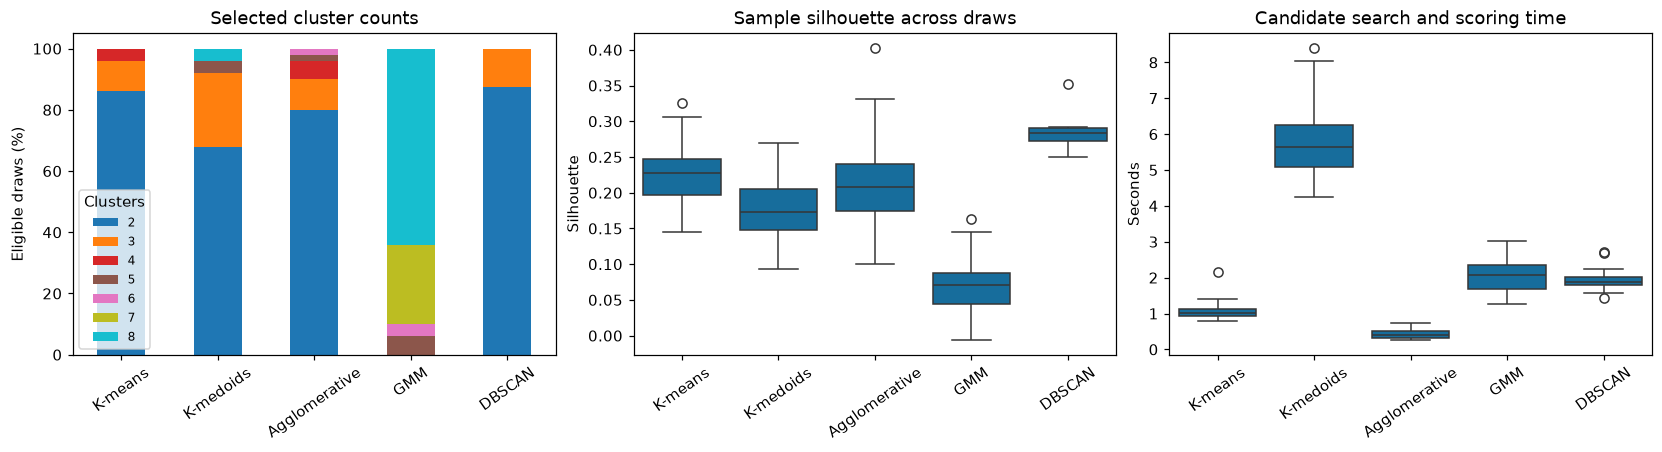

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
cluster_frequency_pct.plot.bar(stacked=True, colormap="tab10", ax=axes[0])
axes[0].set(title="Selected cluster counts", xlabel="", ylabel="Eligible draws (%)")
axes[0].legend(title="Clusters", fontsize=8)
sns.boxplot(data=selected_results, x="Model", y="Silhouette_sample", order=list(model_functions), ax=axes[1])
axes[1].set(title="Sample silhouette across draws", xlabel="", ylabel="Silhouette")
sns.boxplot(data=results, x="Model", y="Model_seconds", order=list(model_functions), ax=axes[2])
axes[2].set(title="Candidate search and scoring time", xlabel="", ylabel="Seconds")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
fig.savefig(RESULTS_DIR / "model_performance.png", dpi=160)
plt.show()

### Membership and profile stability across feature draws

Compare up to **1,000 reproducibly sampled pairs of eligible runs per model**, using all dates assigned in both runs. ARI and AMI do not require matching numeric labels and can compare different cluster counts. DBSCAN noise is excluded rather than treated as a common economic state; `Shared_assigned_pct` reports the retained overlap. A pair needs at least two observed groups from each fit on that overlap.

For equal-count pairs, match clusters by maximizing overlapping membership. Report mean and minimum matched Jaccard overlap using each cluster's full assigned membership. Compare the matched 51-variable profile means and within-cluster standard deviations using RMS distance in common standardized units: lower is more similar. Both profile distances are omitted when counts differ; count agreement, profile agreement and membership agreement are distinct outcomes. Pair comparisons share runs and are descriptive, not independent statistical tests.

In [27]:
# Standard deviations on the same fixed transformed/scaled panel.
profile_std_runs = {
    key: profile_scaled_df.loc[labels >= 0].groupby(labels[labels >= 0]).std(ddof=0).to_numpy()
    for key, labels in label_runs.items()
}

def compare_runs(name, repeat_a, repeat_b):
    a, b = label_runs[(name, repeat_a)], label_runs[(name, repeat_b)]
    common = (a >= 0) & (b >= 0)
    ids_a, ids_b = np.unique(a[a >= 0]), np.unique(b[b >= 0])
    row = {"Model": name, "Repeat_a": repeat_a, "Repeat_b": repeat_b,
           "Shared_assigned_pct": 100 * common.mean(), "Same_count": len(ids_a) == len(ids_b),
           "ARI": np.nan, "AMI": np.nan, "Jaccard_mean": np.nan,
           "Jaccard_min": np.nan, "Profile_RMS_z": np.nan, "Profile_std_RMS_z": np.nan}
    if min(len(np.unique(a[common])), len(np.unique(b[common]))) < 2:
        return row
    row["ARI"] = adjusted_rand_score(a[common], b[common])
    row["AMI"] = adjusted_mutual_info_score(a[common], b[common])
    if row["Same_count"]:
        overlap = np.zeros((len(ids_a), len(ids_b)), dtype=int)
        np.add.at(overlap, (np.searchsorted(ids_a, a[common]), np.searchsorted(ids_b, b[common])), 1)
        matched_a, matched_b = linear_sum_assignment(-overlap)
        size_a = np.array([(a == cluster).sum() for cluster in ids_a])
        size_b = np.array([(b == cluster).sum() for cluster in ids_b])
        intersection = overlap[matched_a, matched_b]
        jaccard = intersection / (size_a[matched_a] + size_b[matched_b] - intersection)
        difference = profile_runs[(name, repeat_a)][matched_a] - profile_runs[(name, repeat_b)][matched_b]
        std_difference = profile_std_runs[(name, repeat_a)][matched_a] - profile_std_runs[(name, repeat_b)][matched_b]
        row.update(Jaccard_mean=jaccard.mean(), Jaccard_min=jaccard.min(),
                   Profile_RMS_z=np.sqrt(np.mean(difference ** 2)),
                   Profile_std_RMS_z=np.sqrt(np.mean(std_difference ** 2)))
    return row


stability_rows = []
pair_rng = np.random.default_rng(321)
for name in model_functions:
    repeats = sorted(repeat for model, repeat in label_runs if model == name)
    pairs = list(combinations(repeats, 2))
    if len(pairs) > 1000:
        pair_indices = np.sort(pair_rng.choice(len(pairs), 1000, replace=False))
        pairs = [pairs[i] for i in pair_indices]
    stability_rows.extend(compare_runs(name, a, b) for a, b in pairs)

stability_pairs = pd.DataFrame(stability_rows)
stability_summary = stability_pairs.groupby("Model").agg(
    Pairs=("Repeat_a", "count"), Valid_ARI_pairs=("ARI", "count"),
    Same_count_share=("Same_count", "mean"), ARI_median=("ARI", "median"),
    ARI_p10=("ARI", lambda values: values.quantile(0.10)),
    AMI_median=("AMI", "median"), Shared_assigned_mean_pct=("Shared_assigned_pct", "mean"),
    Matched_profile_pairs=("Profile_RMS_z", "count"),
    Profile_RMS_z_median=("Profile_RMS_z", "median"),
    Profile_std_RMS_z_median=("Profile_std_RMS_z", "median"),
    Jaccard_mean_median=("Jaccard_mean", "median"),
    Worst_cluster_Jaccard_median=("Jaccard_min", "median"),
).reindex(model_functions)
stability_summary["Same_count_pct"] = 100 * stability_summary.pop("Same_count_share")
display(stability_summary.round(3))

,Pairs,Valid_ARI_pairs,ARI_median,ARI_p10,AMI_median,Shared_assigned_mean_pct,Matched_profile_pairs,Profile_RMS_z_median,Profile_std_RMS_z_median,Jaccard_mean_median,Worst_cluster_Jaccard_median,Same_count_pct
Model,,,,,,,,,,,,
K-means,1000,1000,0.310,0.015,0.244,100.000,740,0.191,0.108,0.644,0.513,74.0
K-medoids,1000,1000,0.123,0.012,0.139,100.000,516,0.315,0.192,0.448,0.376,51.6
Agglomerative,1000,1000,0.146,0.003,0.129,100.000,658,0.362,0.200,0.488,0.302,65.8
GMM,1000,1000,0.301,0.160,0.436,100.000,472,0.501,0.340,0.316,0.050,47.2
DBSCAN,28,28,0.989,0.839,0.971,87.745,21,0.136,0.166,0.854,0.797,75.0


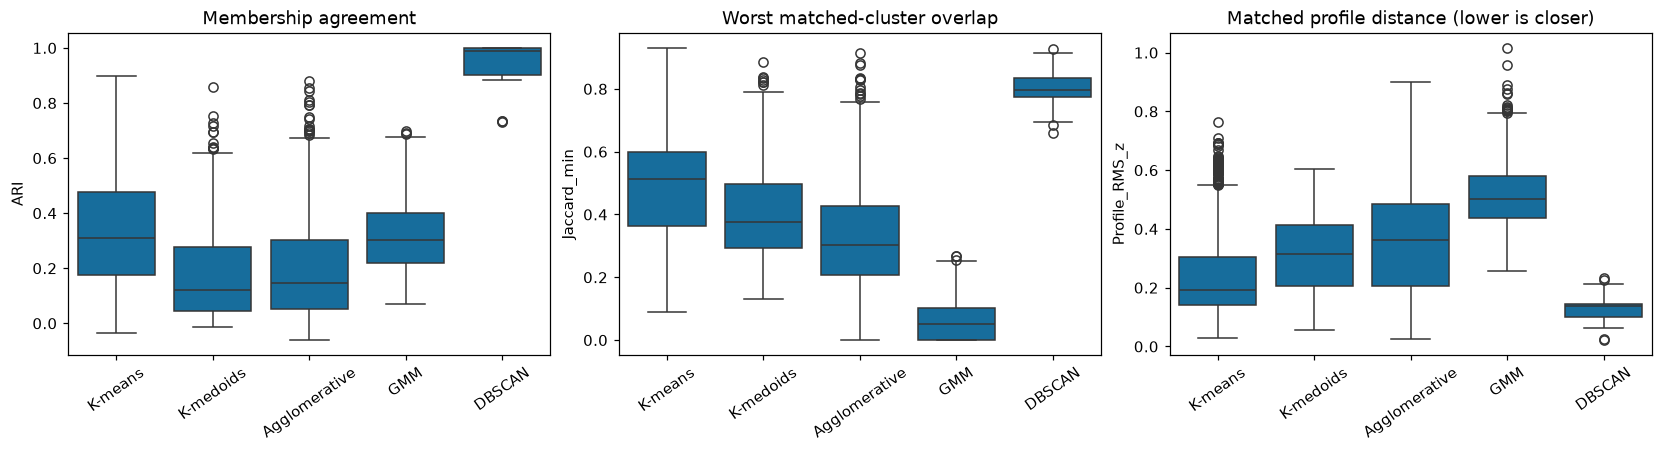

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, metric, title in zip(axes,
        ["ARI", "Jaccard_min", "Profile_RMS_z"],
        ["Membership agreement", "Worst matched-cluster overlap", "Matched profile distance (lower is closer)"]):
    sns.boxplot(data=stability_pairs, x="Model", y=metric, order=list(model_functions), ax=ax)
    ax.set(title=title, xlabel="")
    ax.tick_params(axis="x", rotation=35)
fig.savefig(RESULTS_DIR / "model_stability.png", dpi=160)
plt.show()

### Co-assignment over time and feature-selection audit

The heatmaps use 300 evenly spaced observed dates, in chronological order. A cell is the fraction of eligible runs assigning those two dates to the same cluster. For DBSCAN its denominator counts only runs assigning **both** dates, so two noise labels never create artificial agreement. Missing cells mean no jointly assigned runs. This is a sampled-date view, not the full date-by-date consensus matrix.

Each random candidate feature has marginal inclusion probability 5/25 per draw under the balanced sampler. The fixed S&P return has inclusion probability one and is recorded as `Selection="Fixed"`. Expected counts are a sampling reference, not a requirement that every feature occur equally often. The audit records realized counts, family representation and duplicate subsets.

Distinct feature subsets: 50 / 50
Fixed S&P log-return appearances: 50 / 50


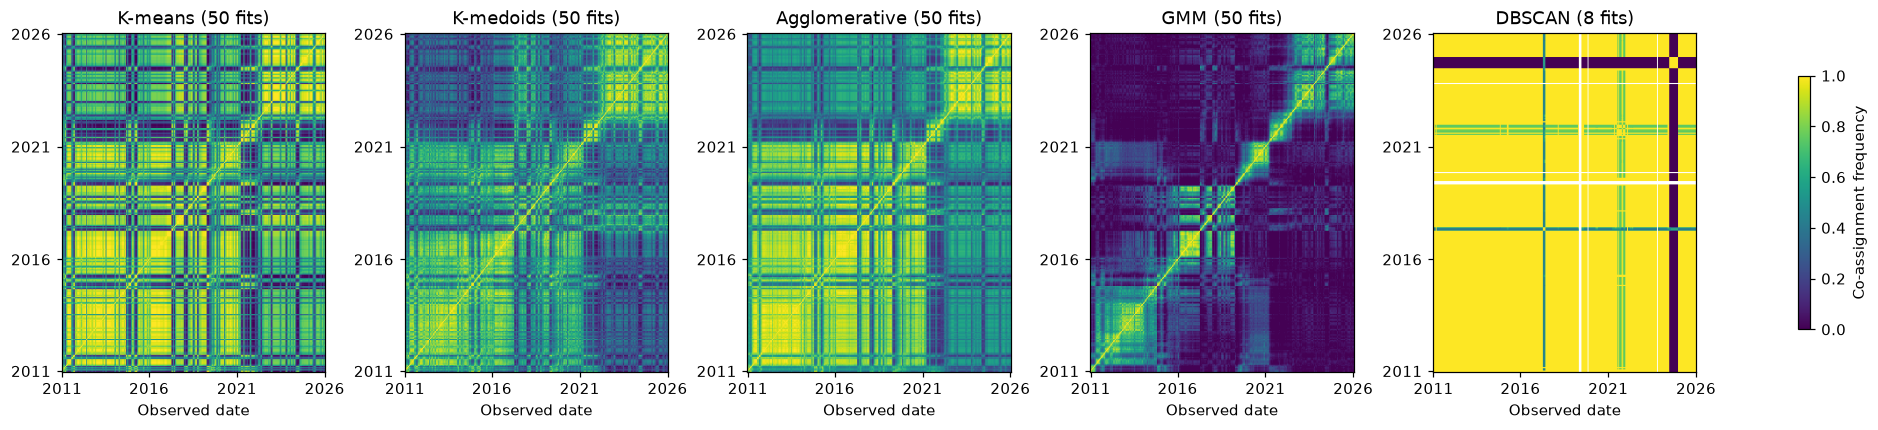

,block,family,Times_selected,Expected_count
feature,,,,
policy_rate,macro_market,rates_policy,11,10.0
tbill_3m,macro_market,rates_policy,7,10.0
nominal_yield_30y,macro_market,rates_policy,11,10.0
slope_10y_2y,macro_market,rates_policy,12,10.0
yield_change_21d,macro_market,rates_policy,7,10.0
slope_change_21d,macro_market,rates_policy,7,10.0
breakeven_5y,macro_market,inflation_real_rates,12,10.0
breakeven_10y,macro_market,inflation_real_rates,11,10.0
real_yield_5y,macro_market,inflation_real_rates,6,10.0


In [31]:
consensus_indices = np.unique(np.linspace(0, len(X_complete) - 1, min(300, len(X_complete)), dtype=int))
consensus_dates = X_complete.index[consensus_indices]
consensus_matrices, consensus_denominators = {}, {}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), layout="constrained")
for ax, name in zip(axes, model_functions):
    numerator = np.zeros((len(consensus_indices), len(consensus_indices)))
    denominator = np.zeros_like(numerator)
    for (model, repeat), labels in label_runs.items():
        if model != name:
            continue
        sample = labels[consensus_indices]
        jointly_assigned = np.outer(sample >= 0, sample >= 0)
        numerator += (sample[:, None] == sample[None, :]) & jointly_assigned
        denominator += jointly_assigned
    matrix = np.divide(numerator, denominator, out=np.full_like(numerator, np.nan), where=denominator > 0)
    consensus_matrices[name], consensus_denominators[name] = matrix, denominator
    image = ax.imshow(matrix, origin="lower", vmin=0, vmax=1, cmap="viridis", aspect="auto")
    eligible_count = sum(model == name for model, repeat in label_runs)
    if not np.isfinite(matrix).any():
        ax.text(0.5, 0.5, "No eligible fits", transform=ax.transAxes, ha="center", va="center")
    elif eligible_count == 1:
        ax.text(0.5, 0.5, "Only one eligible fit", transform=ax.transAxes, ha="center", va="center",
                bbox={"facecolor": "white", "alpha": 0.85})
    ticks = np.linspace(0, len(consensus_dates) - 1, 4, dtype=int)
    ax.set(xticks=ticks, yticks=ticks, xticklabels=consensus_dates[ticks].year,
           yticklabels=consensus_dates[ticks].year, title=f"{name} ({eligible_count} fits)", xlabel="Observed date")
fig.colorbar(image, ax=axes.tolist(), label="Co-assignment frequency", shrink=0.75)
fig.savefig(RESULTS_DIR / "coassignment.png", dpi=160)
plt.show()

feature_usage = feature_catalog.join(feature_draws["Feature"].value_counts().rename("Times_selected")).fillna({"Times_selected": 0})
feature_usage["Times_selected"] = feature_usage["Times_selected"].astype(int)
feature_usage["Expected_count"] = N_REPEATS * 5 / 25
family_usage = pd.crosstab(feature_draws["Repeat"], feature_draws["Family"])
subset_keys = feature_draws.groupby("Repeat")["Feature"].apply(lambda values: tuple(sorted(values)))
display(feature_usage)
print(f"Distinct feature subsets: {subset_keys.nunique()} / {N_REPEATS}")
print(f"Fixed S&P log-return appearances: {feature_draws['Feature'].eq(FIXED_FEATURE).sum()} / {N_REPEATS}")


### Example equity-focused profiles

The first three K-means repetitions below show original-unit profile means on the same variables. S&P returns and momentum are decimal log returns; yield/spread/volatility columns retain their documented published units. Cluster numbers are local to each fit; the matching statistics above handle label permutations. Full means and population standard deviations for all 51 variables are exported.


In [32]:
profile_means.loc[
    profile_means["Model"].eq("K-means") & profile_means["Repeat"].le(3),
    ["Repeat", "Cluster", "sp500_log_return", "breakeven_10y", "real_yield_10y",
     "baa_10y_spread", "vix", "sp500_realized_vol_21d", "sp500_momentum_63d"],
].round(4)


Out[2]: 
    Repeat  Cluster  ...  sp500_realized_vol_21d  sp500_momentum_63d
0        1      0.0  ...                 19.3499             -0.0178
1        1      1.0  ...                 11.3588              0.0557
15       2      0.0  ...                 13.8462              0.0319
16       2      1.0  ...                 14.3548              0.0297
29       3      0.0  ...                 21.2751             -0.0065
30       3      1.0  ...                  9.9640              0.0522

[6 rows x 9 columns]


## S&P 500 return profiles across randomized runs

Focus on the equity outcome: **mean daily S&P 500 log return within each cluster**, alongside daily volatility, loss frequency and cluster size. Reuse the saved memberships; these cells do not refit the models. Return figures below are in **daily log-return percentage units**, `100 * r`, not recovered simple returns or annualized returns. One basis point is `0.0001` in decimal return units.

Two comparisons serve different purposes:

- **Return-ranked profiles:** order clusters by their mean S&P return within each fit. Rank 1 is the lowest mean; the highest rank depends on the selected K. This removes arbitrary numeric label order, but does not match economic states or memberships. The ordering and the positive high-minus-low gap are mechanical.
- **Membership-matched profiles:** for the existing equal-K run pairs, match clusters using date overlap, then compare their return means and volatility. This can detect changes that return sorting might hide.

S&P log return is a mandatory clustering input, so these are **in-sample descriptive profiles**. Mean-return separation is partly an intended consequence of the fit, not evidence of future predictability. The boxes and quantiles describe variation over feature draws; they are not confidence intervals for expected returns. DBSCAN results remain conditional on its eligible draws, and noise is excluded.

In [47]:
equity_returns = outcomes.loc[X_complete.index, "sp500_log_return"]
unconditional_mean_pct = 100 * equity_returns.mean()
unconditional_vol_pct = 100 * equity_returns.std(ddof=0)
equity_rows, separation_rows = [], []

for (name, repeat), labels in label_runs.items():
    assigned = labels >= 0
    groups = equity_returns.loc[assigned].groupby(labels[assigned])
    profile = groups.agg(Mean="mean", Count="size")
    profile["Std"] = groups.std(ddof=0)
    profile["Loss_probability_pct"] = 100 * equity_returns.loc[assigned].lt(0).groupby(labels[assigned]).mean()
    profile["P05_log_pct"] = 100 * groups.quantile(0.05)
    profile["P95_log_pct"] = 100 * groups.quantile(0.95)
    profile.index.name = "Cluster"
    profile = profile.reset_index().sort_values(["Mean", "Cluster"])
    profile["Return_rank"] = np.arange(1, len(profile) + 1)
    profile["Mean_log_pct"] = 100 * profile["Mean"]
    profile["Std_log_pct"] = 100 * profile["Std"]
    profile["Share_all_dates_pct"] = 100 * profile["Count"] / len(equity_returns)
    profile["Share_assigned_pct"] = 100 * profile["Count"] / assigned.sum()
    profile["Clusters"] = len(profile)
    profile["Model"], profile["Repeat"] = name, repeat
    equity_rows.append(profile)

    assigned_mean = equity_returns.loc[assigned].mean()
    total_ss = ((equity_returns.loc[assigned] - assigned_mean) ** 2).sum()
    between_ss = (profile["Count"] * (profile["Mean"] - assigned_mean) ** 2).sum()
    separation_rows.append({
        "Model": name, "Repeat": repeat, "Clusters": len(profile),
        "Coverage_pct": 100 * assigned.mean(),
        "Low_mean_log_pct": profile["Mean_log_pct"].min(),
        "High_mean_log_pct": profile["Mean_log_pct"].max(),
        "High_minus_low_bp": 10000 * (profile["Mean"].max() - profile["Mean"].min()),
        "Return_mean_R2_pct": 100 * between_ss / total_ss if total_ss > 0 else np.nan,
    })

equity_profiles = pd.concat(equity_rows, ignore_index=True)
return_separation = pd.DataFrame(separation_rows).merge(
    selected_results[["Model", "Repeat", "Silhouette_sample"]], on=["Model", "Repeat"], validate="one_to_one")
equity_profiles[["Model", "Repeat", "Clusters", "Cluster", "Return_rank", "Count",
                 "Share_all_dates_pct", "Mean_log_pct", "Std_log_pct", "Loss_probability_pct"]].head(12).round(4)

Out[1]: 
            Model  Repeat  ...  Std_log_pct  Loss_probability_pct
0         K-means       1  ...       1.5422               64.5267
1         K-means       1  ...       0.6186               36.0663
2       K-medoids       1  ...       1.2902               90.5054
3       K-medoids       1  ...       0.8617               42.0118
4       K-medoids       1  ...       0.7605               32.5013
5   Agglomerative       1  ...       1.1289               45.3400
6   Agglomerative       1  ...       0.8638               46.2451
7             GMM       1  ...       3.4609               64.4068
8             GMM       1  ...       1.2873               61.6402
9             GMM       1  ...       0.5961               46.9065
10            GMM       1  ...       0.8828               44.7641
11            GMM       1  ...       0.8438               44.6875

[12 rows x 10 columns]


### Mean-return heatmaps — every randomized fit

Rows are randomized repetitions, **not calendar time**. Columns are within-fit return ranks, not the original cluster IDs. The same colour scale is used for every model, capped at the 98th percentile of absolute cluster means for contrast; larger extremes saturate at the colour-bar endpoints and remain fully reported in the tables and other plots. Grey cells indicate an absent rank or a run without an eligible result. A higher rank is higher by construction; compare the actual levels and their variation across rows.

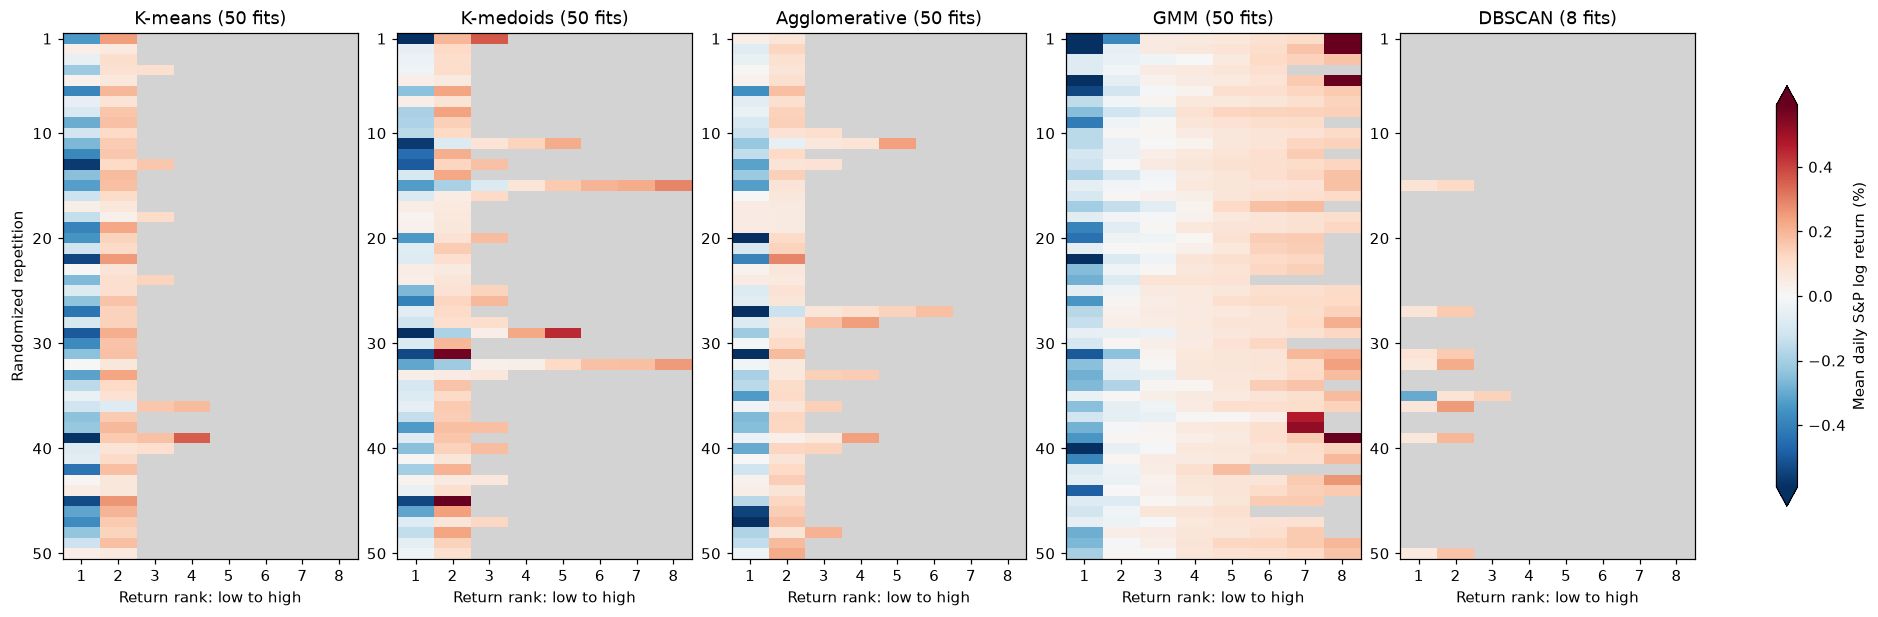

In [48]:
max_rank = int(equity_profiles["Return_rank"].max())
colour_limit = equity_profiles["Mean_log_pct"].abs().quantile(0.98)
fig, axes = plt.subplots(1, 5, figsize=(17, 5.5), layout="constrained")
for ax, name in zip(axes, model_functions):
    values = equity_profiles.loc[equity_profiles["Model"].eq(name)]
    grid = values.pivot(index="Repeat", columns="Return_rank", values="Mean_log_pct")
    grid = grid.reindex(index=range(1, N_REPEATS + 1), columns=range(1, max_rank + 1))
    ax.set_facecolor("lightgrey")
    image = ax.imshow(np.ma.masked_invalid(grid.to_numpy()), aspect="auto", cmap="RdBu_r",
                      vmin=-colour_limit, vmax=colour_limit, interpolation="nearest")
    ticks = np.array([1, 10, 20, 30, 40, N_REPEATS])
    ticks = np.unique(ticks[ticks <= N_REPEATS])
    ax.set(xticks=np.arange(max_rank), xticklabels=np.arange(1, max_rank + 1),
           yticks=ticks - 1, yticklabels=ticks, xlabel="Return rank: low to high",
           title=f"{name} ({values['Repeat'].nunique()} fits)")
axes[0].set_ylabel("Randomized repetition")
fig.colorbar(image, ax=axes.tolist(), label="Mean daily S&P log return (%)", shrink=0.8, extend="both")
fig.savefig(RESULTS_DIR / "equity_mean_heatmaps.png", dpi=160)
plt.show()

### Comparable profile distributions — condition on the same selected K

For each model, use only repetitions selecting its most frequent cluster count. Titles report both that count and the number of retained draws. The top row compares mean daily log returns; the bottom compares daily log-return volatility. Faint points show individual randomized fits. Dashed lines mark the unconditional complete-sample mean and volatility. Different models can have different modal K; these panels do not rank model quality.

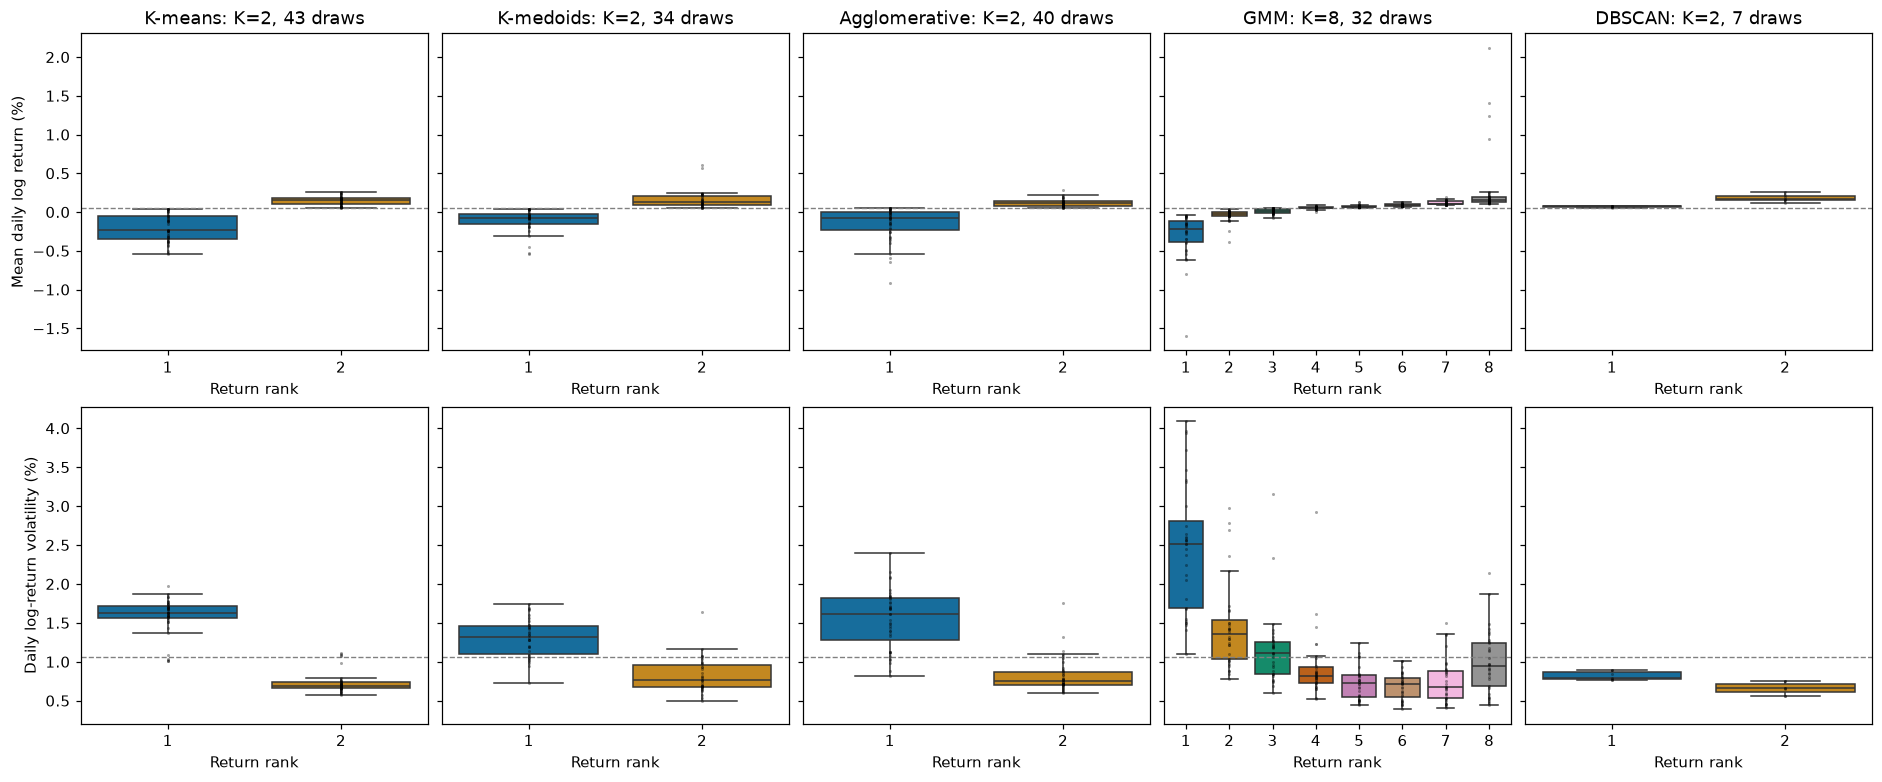

Draws  ...  Cluster_share_median_pct
Model         Clusters Return_rank         ...                          
Agglomerative 2        1               40  ...                   29.0496
                       2               40  ...                   70.9504
DBSCAN        2        1                7  ...                   85.5372
                       2                7  ...                    3.1956
GMM           8        1               32  ...                    5.6749
                       2               32  ...                    9.7658
                       3               32  ...                   11.3361
                       4               32  ...                   18.4986
                       5               32  ...                   15.7300
                       6               32  ...                   14.3113
                       7               32  ...                   13.5124
                       8               32  ...                    7.6171
K-means       2        1               43  ...                   27.7686
                       2               43  ...                   72.2314
K-medoids     2        1               34  ...                   41.6391
                       2               34  ...                   58.3609

[16 rows x 8 columns]

In [49]:
modal_counts = performance_summary["Modal_clusters"].dropna().astype(int)
modal_equity_profiles = equity_profiles.loc[
    equity_profiles["Clusters"].eq(equity_profiles["Model"].map(modal_counts))
].copy()

fig, axes = plt.subplots(2, 5, figsize=(17, 7), sharey="row", layout="constrained")
for j, name in enumerate(model_functions):
    values = modal_equity_profiles.loc[modal_equity_profiles["Model"].eq(name)]
    for i, (metric, baseline) in enumerate([
        ("Mean_log_pct", unconditional_mean_pct), ("Std_log_pct", unconditional_vol_pct)
    ]):
        ax = axes[i, j]
        if not values.empty:
            sns.boxplot(data=values, x="Return_rank", y=metric, hue="Return_rank",
                        palette="colorblind", legend=False, showfliers=False, ax=ax)
            sns.stripplot(data=values, x="Return_rank", y=metric, color="black",
                          jitter=False, size=2, alpha=0.35, ax=ax)
        ax.axhline(baseline, color="grey", linestyle="--", linewidth=0.9)
        ax.set(xlabel="Return rank", ylabel="")
    k = modal_counts.get(name, np.nan)
    axes[0, j].set_title(f"{name}: K={k}, {values['Repeat'].nunique()} draws")
axes[0, 0].set_ylabel("Mean daily log return (%)")
axes[1, 0].set_ylabel("Daily log-return volatility (%)")
fig.savefig(RESULTS_DIR / "equity_profile_distributions.png", dpi=160)
plt.show()

equity_profile_summary = equity_profiles.groupby(["Model", "Clusters", "Return_rank"]).agg(
    Draws=("Repeat", "nunique"),
    Mean_return_median_pct=("Mean_log_pct", "median"),
    Mean_return_p10_pct=("Mean_log_pct", lambda values: values.quantile(0.10)),
    Mean_return_p90_pct=("Mean_log_pct", lambda values: values.quantile(0.90)),
    Positive_mean_draws_pct=("Mean_log_pct", lambda values: 100 * values.gt(0).mean()),
    Volatility_median_pct=("Std_log_pct", "median"),
    Loss_probability_median_pct=("Loss_probability_pct", "median"),
    Cluster_share_median_pct=("Share_all_dates_pct", "median"),
)
modal_equity_summary = equity_profile_summary.reset_index()
modal_equity_summary = modal_equity_summary.loc[
    modal_equity_summary["Clusters"].eq(modal_equity_summary["Model"].map(modal_counts))
].set_index(["Model", "Clusters", "Return_rank"])
display(modal_equity_summary.round(4))

### How much equity-return separation does each fit produce?

`Return_mean_R2_pct` measures the fraction of assigned-sample daily return variation associated with differences in cluster means:

$$R^2_{\mathrm{return}}=
\frac{\sum_k n_k(\bar r_k-\bar r_{\mathrm{assigned}})^2}
{\sum_{t:\,c_t\geq0}(r_t-\bar r_{\mathrm{assigned}})^2}.$$

This is an in-sample variance decomposition, not a predictive R-squared. More clusters can increase mean separation; compare results within the same K. For DBSCAN, the denominator uses only assigned dates, so noise exclusion also changes the comparison. The population plot shows whether extreme mean profiles belong to small groups. The second plot compares geometric silhouette with return-mean separation; marker size indicates K. The high-minus-low mean gap is descriptive and positive by construction, not a strategy return.

This decomposition concerns differences in equity-return means. It is separate from PCA explained variance and does not measure separation in conditional volatility; states can have similar means but different risk profiles.


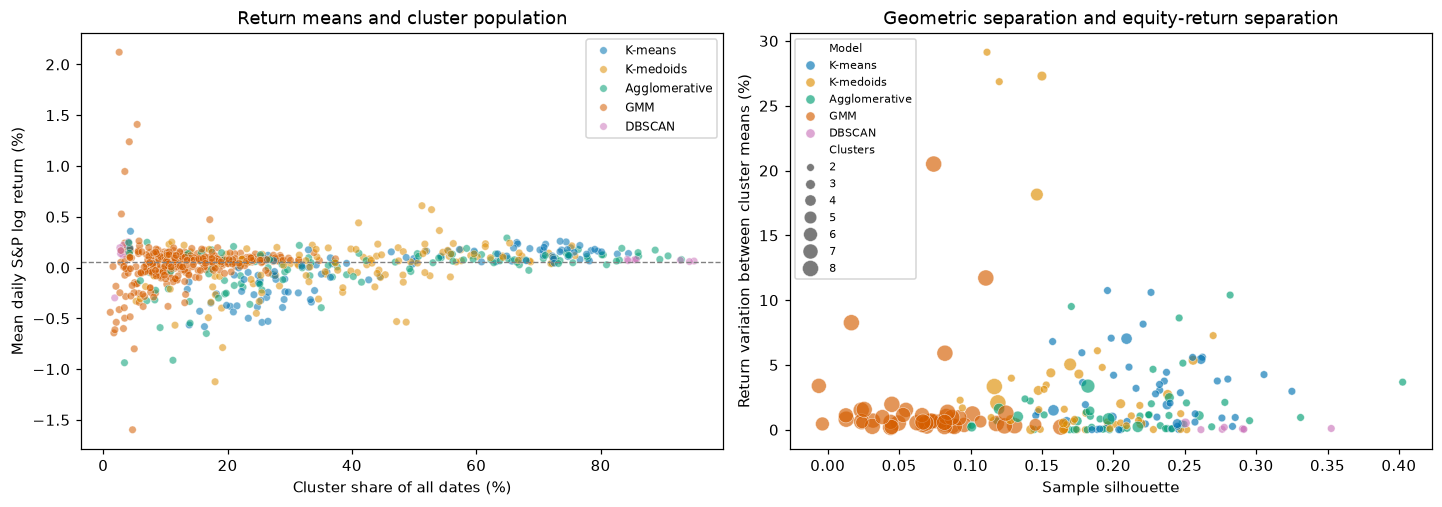

Draws  ...  Coverage_mean_pct
Model         Clusters         ...                   
Agglomerative 2            40  ...            100.000
              3             5  ...            100.000
              4             3  ...            100.000
              5             1  ...            100.000
              6             1  ...            100.000
DBSCAN        2             7  ...             92.003
              3             1  ...             90.386
GMM           5             3  ...            100.000
              6             2  ...            100.000
              7            13  ...            100.000
              8            32  ...            100.000
K-means       2            43  ...            100.000
              3             5  ...            100.000
              4             2  ...            100.000
K-medoids     2            34  ...            100.000
              3            12  ...            100.000
              5             2  ...            100.000
              8             2  ...            100.000

[18 rows x 6 columns]

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
sns.scatterplot(data=equity_profiles, x="Share_all_dates_pct", y="Mean_log_pct",
                hue="Model", hue_order=list(model_functions), alpha=0.55, s=24, ax=axes[0])
axes[0].axhline(unconditional_mean_pct, color="grey", linestyle="--", linewidth=0.9)
axes[0].set(xlabel="Cluster share of all dates (%)", ylabel="Mean daily S&P log return (%)",
            title="Return means and cluster population")
sns.scatterplot(data=return_separation, x="Silhouette_sample", y="Return_mean_R2_pct",
                hue="Model", hue_order=list(model_functions), size="Clusters", sizes=(25, 110),
                alpha=0.65, ax=axes[1])
axes[1].set(xlabel="Sample silhouette", ylabel="Return variation between cluster means (%)",
            title="Geometric separation and equity-return separation")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=7, loc="upper left")
fig.savefig(RESULTS_DIR / "equity_return_separation.png", dpi=160)
plt.show()

return_separation_summary = return_separation.groupby(["Model", "Clusters"]).agg(
    Draws=("Repeat", "count"),
    Mean_gap_median_bp=("High_minus_low_bp", "median"),
    Mean_gap_p10_bp=("High_minus_low_bp", lambda values: values.quantile(0.10)),
    Mean_gap_p90_bp=("High_minus_low_bp", lambda values: values.quantile(0.90)),
    Return_R2_median_pct=("Return_mean_R2_pct", "median"),
    Coverage_mean_pct=("Coverage_pct", "mean"),
)
display(return_separation_summary.round(3))

### Do the same membership-matched clusters keep similar return means?

Use the existing sampled run pairs with equal selected cluster counts and valid shared memberships. Match groups by maximum overlap of assigned dates, **not by return ordering**, then calculate RMS differences between their mean log returns and population standard deviations. Distances are in **daily return basis points**: lower values mean closer profiles. Matching uses the same overlap rule as the earlier stability section. Pairwise differences can be small even when memberships differ, so also inspect ARI and the population profiles.

The plots pool equal-K comparisons within each model; the table separates them by K. Pair counts are shown on the axes, and comparisons share runs.


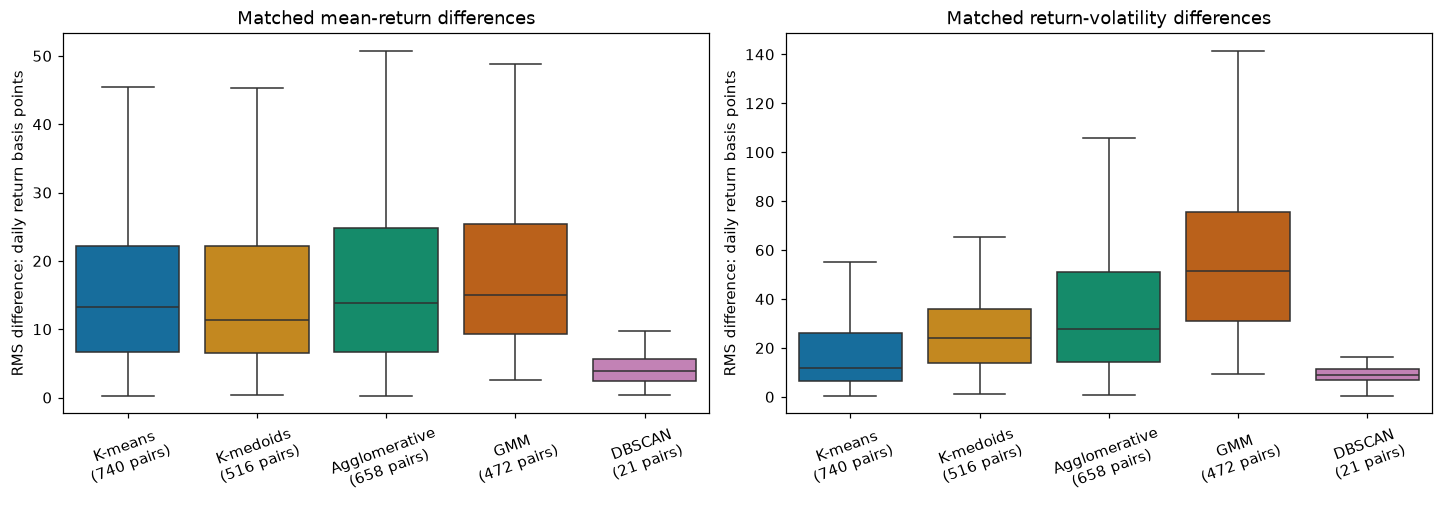

Pairs  ...  ARI_median
Model         Clusters         ...            
Agglomerative 2           646  ...       0.145
              3             9  ...       0.544
              4             3  ...       0.314
DBSCAN        2            21  ...       1.000
GMM           5             2  ...       0.212
              6             1  ...       0.152
              7            67  ...       0.225
              8           402  ...       0.342
K-means       2           730  ...       0.387
              3            10  ...       0.420
K-medoids     2           460  ...       0.063
              3            55  ...       0.346
              8             1  ...       0.169

[13 rows x 6 columns]

In [51]:
equity_lookup = {
    key: group.set_index("Cluster").sort_index()
    for key, group in equity_profiles.groupby(["Model", "Repeat"])
}
matched_equity_rows = []
matched_pairs = stability_pairs.loc[stability_pairs["Profile_RMS_z"].notna()]
for pair in matched_pairs.itertuples():
    a = label_runs[(pair.Model, pair.Repeat_a)]
    b = label_runs[(pair.Model, pair.Repeat_b)]
    ids_a, ids_b = np.unique(a[a >= 0]), np.unique(b[b >= 0])
    common = (a >= 0) & (b >= 0)
    overlap = np.zeros((len(ids_a), len(ids_b)), dtype=int)
    np.add.at(overlap, (np.searchsorted(ids_a, a[common]), np.searchsorted(ids_b, b[common])), 1)
    matched_a, matched_b = linear_sum_assignment(-overlap)
    profile_a = equity_lookup[(pair.Model, pair.Repeat_a)].loc[ids_a]
    profile_b = equity_lookup[(pair.Model, pair.Repeat_b)].loc[ids_b]
    mean_difference_bp = 10000 * (profile_a["Mean"].to_numpy()[matched_a] - profile_b["Mean"].to_numpy()[matched_b])
    std_difference_bp = 10000 * (profile_a["Std"].to_numpy()[matched_a] - profile_b["Std"].to_numpy()[matched_b])
    matched_equity_rows.append({
        "Model": pair.Model, "Repeat_a": pair.Repeat_a, "Repeat_b": pair.Repeat_b,
        "Clusters": len(ids_a), "ARI": pair.ARI,
        "Shared_assigned_pct": pair.Shared_assigned_pct,
        "Mean_RMS_difference_bp": np.sqrt(np.mean(mean_difference_bp ** 2)),
        "Mean_max_abs_difference_bp": np.abs(mean_difference_bp).max(),
        "Vol_RMS_difference_bp": np.sqrt(np.mean(std_difference_bp ** 2)),
    })

matched_equity_pairs = pd.DataFrame(matched_equity_rows)
matched_equity_summary = matched_equity_pairs.groupby(["Model", "Clusters"]).agg(
    Pairs=("Repeat_a", "count"),
    Mean_RMS_median_bp=("Mean_RMS_difference_bp", "median"),
    Mean_RMS_p90_bp=("Mean_RMS_difference_bp", lambda values: values.quantile(0.90)),
    Worst_mean_difference_median_bp=("Mean_max_abs_difference_bp", "median"),
    Vol_RMS_median_bp=("Vol_RMS_difference_bp", "median"),
    ARI_median=("ARI", "median"),
)
pair_counts = matched_equity_pairs["Model"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, metric, title in zip(axes,
        ["Mean_RMS_difference_bp", "Vol_RMS_difference_bp"],
        ["Matched mean-return differences", "Matched return-volatility differences"]):
    sns.boxplot(data=matched_equity_pairs, x="Model", y=metric, hue="Model",
                order=list(model_functions), palette="colorblind", legend=False, showfliers=False, ax=ax)
    ax.set(xlabel="", ylabel="RMS difference: daily return basis points", title=title)
    ax.set_xticks(range(len(model_functions)),
                  [f"{name}\n({pair_counts.get(name, 0)} pairs)" for name in model_functions], rotation=20)
fig.savefig(RESULTS_DIR / "equity_matched_profile_stability.png", dpi=160)
plt.show()
display(matched_equity_summary.round(3))

### DBSCAN context: assigned dates versus excluded noise

The selected DBSCAN profiles omit noise dates. This table compares the assigned and noise subsets within each eligible fit, then summarizes their variation across fits. It helps assess whether seemingly attractive cluster return profiles partly reflect exclusion of negative or volatile observations. Noise is not treated as an additional economic cluster.


In [52]:
noise_rows = []
for (name, repeat), labels in label_runs.items():
    if name != "DBSCAN":
        continue
    for group, mask in [("Assigned", labels >= 0), ("Noise", labels < 0)]:
        values = equity_returns.loc[mask]
        noise_rows.append({
            "Repeat": repeat, "Group": group, "Rows": len(values),
            "Share_pct": 100 * len(values) / len(equity_returns),
            "Mean_log_pct": 100 * values.mean(),
            "Std_log_pct": 100 * values.std(ddof=0),
            "Loss_probability_pct": 100 * values.lt(0).mean() if len(values) else np.nan,
        })
dbscan_return_context = pd.DataFrame(noise_rows, columns=[
    "Repeat", "Group", "Rows", "Share_pct", "Mean_log_pct", "Std_log_pct", "Loss_probability_pct"
])
dbscan_context_summary = dbscan_return_context.groupby("Group").agg(
    Fits=("Repeat", "count"), Share_median_pct=("Share_pct", "median"),
    Mean_log_return_median_pct=("Mean_log_pct", "median"),
    Mean_log_return_p10_pct=("Mean_log_pct", lambda values: values.quantile(0.10)),
    Mean_log_return_p90_pct=("Mean_log_pct", lambda values: values.quantile(0.90)),
    Volatility_median_pct=("Std_log_pct", "median"),
    Loss_probability_median_pct=("Loss_probability_pct", "median"),
)
display(dbscan_context_summary.round(4))


,Fits,Share_median_pct,Mean_log_return_median_pct,Mean_log_return_p10_pct,Mean_log_return_p90_pct,Volatility_median_pct,Loss_probability_median_pct
Group,,,,,,,
Assigned,8,89.573,0.0764,0.0669,0.0811,0.7812,44.7162
Noise,8,10.427,-0.1844,-0.9190,-0.1509,2.4139,53.9779


### Detailed view: K-means fits that selected two clusters

Focus on the most common K-means configuration without forcing other repetitions to have two groups. Points show each retained repetition's lower-mean and higher-mean cluster, ordered within that fit. Repetition numbers are feature draws, not trading dates. The middle panel shows mean return against daily volatility, with cluster population controlling point size. The last panel shows the distribution of high-minus-low mean differences. These are descriptive within-sample contrasts.

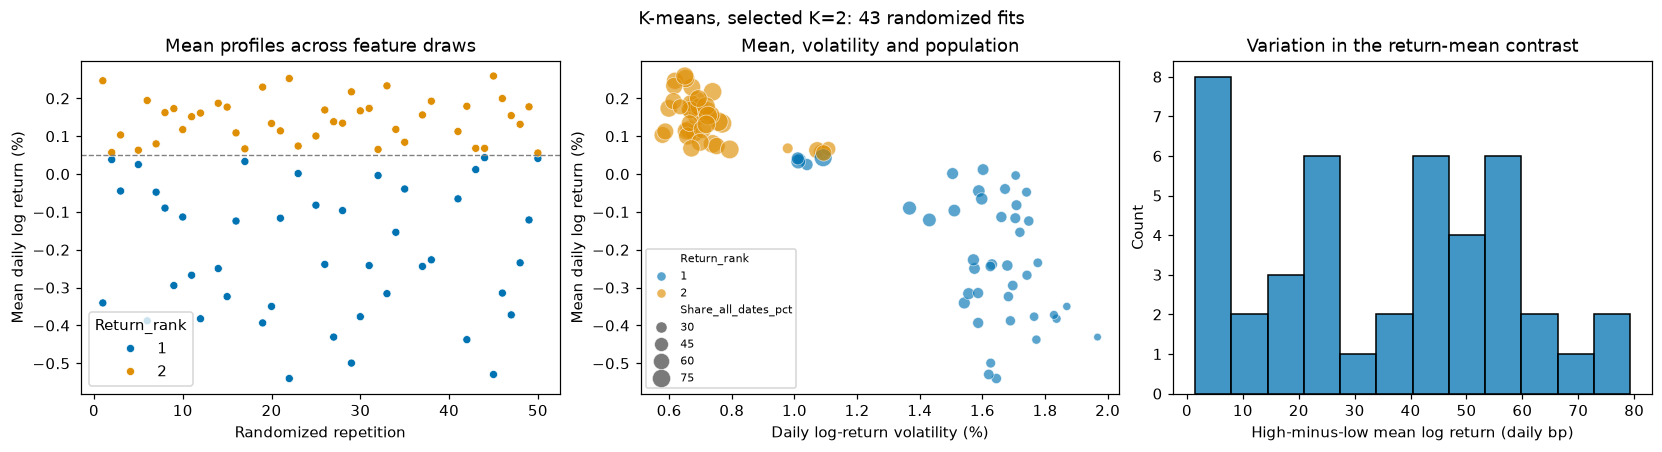

In [53]:
PROFILE_MODEL = "K-means"
PROFILE_K = 2
focus_profiles = equity_profiles.loc[
    equity_profiles["Model"].eq(PROFILE_MODEL) & equity_profiles["Clusters"].eq(PROFILE_K)
]
focus_separation = return_separation.loc[
    return_separation["Model"].eq(PROFILE_MODEL) & return_separation["Clusters"].eq(PROFILE_K)
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
if not focus_profiles.empty:
    sns.scatterplot(data=focus_profiles, x="Repeat", y="Mean_log_pct", hue="Return_rank",
                    palette="colorblind", s=28, ax=axes[0])
    axes[0].axhline(unconditional_mean_pct, color="grey", linestyle="--", linewidth=0.9)
    axes[0].set(xlabel="Randomized repetition", ylabel="Mean daily log return (%)", title="Mean profiles across feature draws")
    sns.scatterplot(data=focus_profiles, x="Std_log_pct", y="Mean_log_pct", hue="Return_rank",
                    size="Share_all_dates_pct", palette="colorblind", sizes=(25, 160), alpha=0.65, ax=axes[1])
    axes[1].set(xlabel="Daily log-return volatility (%)", ylabel="Mean daily log return (%)", title="Mean, volatility and population")
    axes[1].legend(fontsize=7)
    sns.histplot(data=focus_separation, x="High_minus_low_bp", bins=12, ax=axes[2])
    axes[2].set(xlabel="High-minus-low mean log return (daily bp)", title="Variation in the return-mean contrast")
else:
    for ax in axes:
        ax.text(0.5, 0.5, "No eligible fits for this model/count", transform=ax.transAxes, ha="center")
fig.suptitle(f"{PROFILE_MODEL}, selected K={PROFILE_K}: {focus_profiles['Repeat'].nunique()} randomized fits")
fig.savefig(RESULTS_DIR / "equity_focus_profiles.png", dpi=160)
plt.show()

In [54]:
for filename, table in {
    "equity_cluster_profiles": equity_profiles,
    "equity_return_separation": return_separation,
    "equity_matched_pairs": matched_equity_pairs,
    "equity_dbscan_return_context": dbscan_return_context,
}.items():
    table.to_csv(RESULTS_DIR / f"{filename}.csv", index=False)
for filename, table in {
    "equity_profile_summary": equity_profile_summary,
    "equity_modal_profile_summary": modal_equity_summary,
    "equity_return_separation_summary": return_separation_summary,
    "equity_matched_summary": matched_equity_summary,
    "equity_dbscan_context_summary": dbscan_context_summary,
}.items():
    table.to_csv(RESULTS_DIR / f"{filename}.csv")

## S&P 500 log-return-only benchmark

Fit the **same five modelling functions using only standardized daily S&P 500 log return**. Keep the same 3,630 dates, candidate counts, seeds, initialization settings, fixed silhouette dates and eligibility screens. The return is already a log return and is not logged again. There is no PCA truncation in this one-feature benchmark. Each model selects its own configuration; the benchmark is fitted once because there is no feature lottery to repeat. One fit is not a stability test.

Two comparisons are kept separate:

1. **Independently selected benchmark:** compare selected counts, coverage, runtime and agreement with each randomized run. Native geometry scores describe different input spaces, so higher native silhouette alone does not establish an improvement.
2. **Matched-K profile controls:** fit the S&P-only model at the randomized model's most frequent selected count, solely to compare mean/volatility profiles at equal resolution. These controls do not replace either experiment's selected K. Keep the same eligibility rules; show unavailable controls explicitly. DBSCAN has no prescribed K, so its control must be an eligible candidate from the same density grid with the required count.

For a common geometric comparison, score both experiments' selected memberships in **the same S&P-return space** and separately in **the same 51-variable transformed/scaled profile panel**. These are descriptive reference geometries; the first naturally rewards direct separation of returns, while the second emphasizes the broader feature universe. They do not provide independent forecast validation. GMM BIC remains a within-representation selection criterion and is not compared across the one- and eleven-dimensional inputs.

In [55]:
BENCHMARK_DIR = RESULTS_DIR / "sp500_only"
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)
return_values = StandardScaler().fit_transform(outcomes.loc[X_complete.index, [FIXED_FEATURE]])
return_score_distances = squareform(pdist(return_values[score_indices]))
return_distances = squareform(pdist(return_values))

benchmark_rows, benchmark_trials, benchmark_labels = [], [], {}
for name, fit_model in model_functions.items():
    started = perf_counter()
    best, labels, trials = fit_model(return_values, return_values, return_score_distances)
    elapsed = perf_counter() - started
    benchmark_trials.append(trials.assign(Model=name))
    row = {"Model": name, "Selected": best is not None, "Dimensions": 1, "Model_seconds": elapsed}
    if best is not None:
        row.update(best)
        benchmark_labels[name] = labels.astype(np.int16)
    benchmark_rows.append(row)

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_candidates = pd.concat(benchmark_trials, ignore_index=True)
display(benchmark_results[["Model", "Selected", "Clusters", "Coverage_pct", "Min_size",
                           "Silhouette_sample", "Calinski_Harabasz", "Davies_Bouldin", "Model_seconds"]].round(4))

,Model,Selected,Clusters,Coverage_pct,Min_size,Silhouette_sample,Calinski_Harabasz,Davies_Bouldin,Model_seconds
0,K-means,True,5,100.0000,72,0.5497,3839.5800,0.5804,0.6622
1,K-medoids,True,8,100.0000,85,0.5190,3065.6552,0.5982,7.0564
2,Agglomerative,True,2,100.0000,706,0.5424,2719.3075,0.6601,0.4036
3,GMM,True,4,100.0000,92,0.5067,1105.2619,14.8336,0.5469
4,DBSCAN,True,4,92.1488,42,0.2646,355.6556,0.4201,0.2818


### Return profiles and count-matched controls

In [56]:
def sp500_profile(labels):
    assigned = labels >= 0
    groups = equity_returns.loc[assigned].groupby(labels[assigned])
    profile = groups.agg(Mean="mean", Count="size")
    profile["Std"] = groups.std(ddof=0)
    profile["Loss_probability_pct"] = 100 * equity_returns.loc[assigned].lt(0).groupby(labels[assigned]).mean()
    profile.index.name = "Cluster"
    profile = profile.reset_index().sort_values(["Mean", "Cluster"])
    profile["Return_rank"] = np.arange(1, len(profile) + 1)
    profile["Mean_log_pct"] = 100 * profile["Mean"]
    profile["Std_log_pct"] = 100 * profile["Std"]
    profile["Share_all_dates_pct"] = 100 * profile["Count"] / len(equity_returns)
    profile["Clusters"] = len(profile)
    return profile


benchmark_profile_tables = [sp500_profile(labels).assign(Model=name, Source="Selected S&P-only")
                            for name, labels in benchmark_labels.items()]
benchmark_profiles = pd.concat(benchmark_profile_tables, ignore_index=True)

control_labels, control_rows, control_profile_tables = {}, [], []
for name in model_functions:
    if name not in modal_counts:
        continue
    k = int(modal_counts[name])
    started = perf_counter()
    if name == "Agglomerative":
        labels = cut_tree(linkage(return_values, method="ward"), n_clusters=[k]).ravel()
        converged = True
    elif name == "DBSCAN":
        choices = benchmark_candidates.loc[
            benchmark_candidates["Model"].eq(name) & benchmark_candidates["Eligible"]
            & benchmark_candidates["Clusters"].eq(k)
        ]
        if choices.empty:
            control_rows.append({"Model": name, "Target_K": k, "Selected": False})
            continue
        choice = choices.sort_values("Silhouette_sample", ascending=False).iloc[0]
        model = DBSCAN(**json.loads(choice["Parameters"]))
        labels = model.fit_predict(return_values)
        converged = True
    else:
        models = {
            "K-means": KMeans(n_clusters=k, n_init=20, random_state=MODEL_SEED),
            "K-medoids": KMedoids(n_clusters=k, method="fasterpam", metric="precomputed",
                                  init="random", random_state=MODEL_SEED),
            "GMM": GaussianMixture(n_components=k, covariance_type="full", n_init=3,
                                   max_iter=500, reg_covar=1e-5, random_state=MODEL_SEED),
        }
        model = models[name]
        labels = model.fit_predict(return_distances if name == "K-medoids" else return_values)
        converged = bool(getattr(model, "converged_", True))
    scores = evaluate_clusters(labels, return_values, return_score_distances)
    valid = scores["Eligible"] and scores["Clusters"] == k and converged
    control_rows.append({"Model": name, "Target_K": k, "Selected": valid,
                         "Model_seconds": perf_counter() - started, **scores})
    if valid:
        control_labels[name] = labels.astype(np.int16)
        control_profile_tables.append(sp500_profile(labels).assign(Model=name, Source="Matched-K S&P-only"))

control_results = pd.DataFrame(control_rows)
control_profiles = pd.concat(control_profile_tables, ignore_index=True)
display(control_results[["Model", "Target_K", "Selected", "Clusters", "Coverage_pct", "Min_size"]].round(3))
display(benchmark_profiles[["Model", "Clusters", "Return_rank", "Count", "Share_all_dates_pct",
                            "Mean_log_pct", "Std_log_pct", "Loss_probability_pct"]].round(4))

,Model,Target_K,Selected,Clusters,Coverage_pct,Min_size
0,K-means,2,True,2.0,100.0,1133.0
1,K-medoids,2,True,2.0,100.0,1461.0
2,Agglomerative,2,True,2.0,100.0,706.0
3,GMM,8,False,8.0,100.0,6.0
4,DBSCAN,2,False,NaN,NaN,NaN


,Model,Clusters,Return_rank,Count,Share_all_dates_pct,Mean_log_pct,Std_log_pct,Loss_probability_pct
0,K-means,5,1,79,2.1763,-3.4694,1.6292,100.0000
1,K-means,5,2,648,17.8512,-1.0812,0.4434,100.0000
2,K-means,5,3,1900,52.3416,0.0063,0.2670,48.8421
3,K-means,5,4,931,25.6474,0.9874,0.3824,0.0000
4,K-means,5,5,72,1.9835,3.1262,1.5491,0.0000
5,K-medoids,8,1,85,2.3416,-3.3828,1.6017,100.0000
6,K-medoids,8,2,266,7.3278,-1.5077,0.3016,100.0000
7,K-medoids,8,3,428,11.7906,-0.7306,0.1605,100.0000
8,K-medoids,8,4,646,17.7961,-0.2631,0.1094,100.0000
9,K-medoids,8,5,816,22.4793,0.0775,0.1001,28.1863


### Independently selected return profiles

Each black diamond is a cluster in the independently selected S&P-only benchmark. Faint points are clusters from all eligible randomized fits, including their different selected counts. This shows mean/volatility profiles without forcing counts to agree; it does not match individual states. The equal-K controls below provide the separate controlled comparison.


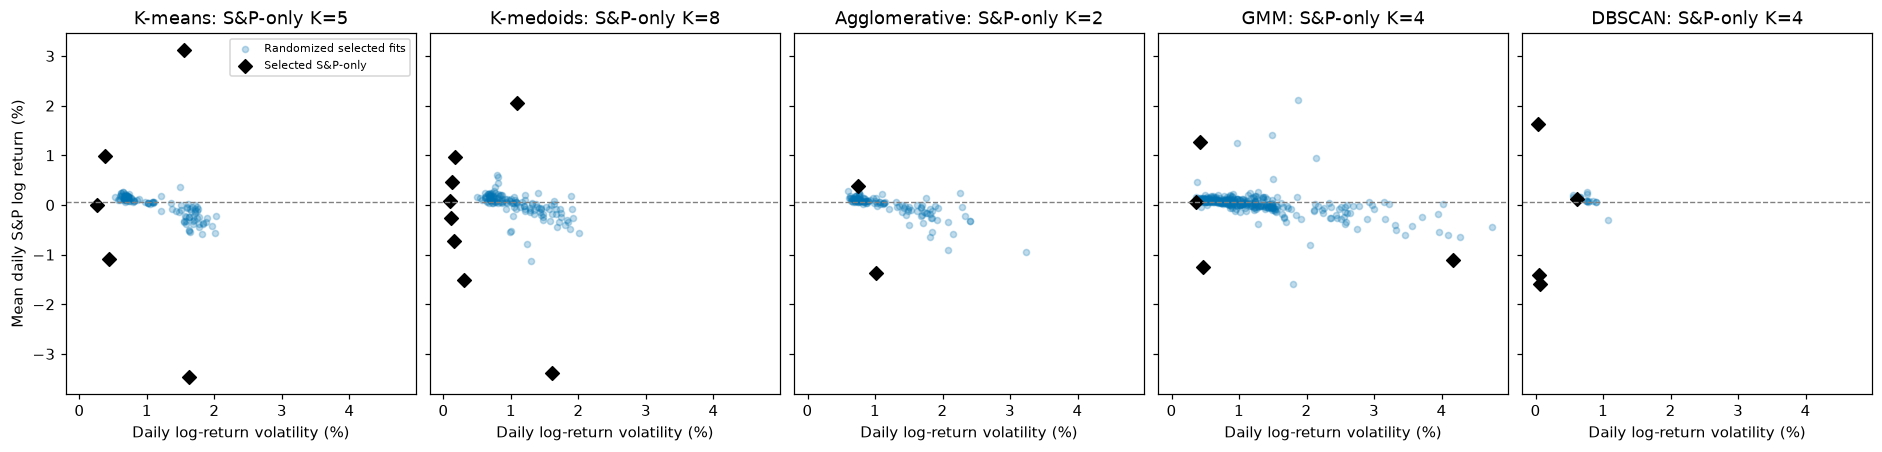

In [62]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes, model_functions):
    randomized = equity_profiles.loc[equity_profiles["Model"].eq(name)]
    baseline = benchmark_profiles.loc[benchmark_profiles["Model"].eq(name)]
    ax.scatter(randomized["Std_log_pct"], randomized["Mean_log_pct"],
               alpha=0.25, s=16, label="Randomized selected fits")
    if not baseline.empty:
        ax.scatter(baseline["Std_log_pct"], baseline["Mean_log_pct"], marker="D", color="black",
                   s=40, label="Selected S&P-only")
    ax.axhline(unconditional_mean_pct, color="grey", linestyle="--", linewidth=0.9)
    k = int(baseline["Clusters"].iloc[0]) if len(baseline) else "none"
    ax.set(title=f"{name}: S&P-only K={k}", xlabel="Daily log-return volatility (%)")
axes[0].set_ylabel("Mean daily S&P log return (%)")
axes[0].legend(fontsize=7)
fig.savefig(BENCHMARK_DIR / "selected_return_profiles.png", dpi=160)
plt.show()


### Score both sets of memberships in common reference spaces

The randomized boxes contain one selected fit per eligible draw. Black diamonds are the independently selected S&P-only benchmark, scored in exactly the same reference space. No model is reselected during this evaluation. Silhouette uses the same fixed 1,000-date sample; Calinski–Harabasz and Davies–Bouldin use all assigned dates. DBSCAN noise is excluded and coverage remains part of the comparison. Scores on the full panel are in-sample assessments on the available feature universe, not independent held-out evidence. Lower Davies–Bouldin is preferred; larger silhouette and Calinski–Harabasz indicate more separation in the specified geometry.

Fits  ...  Coverage_mean_pct
Reference_space        Model         Source            ...                   
Full 51-variable panel Agglomerative Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
                       DBSCAN        Randomized     8  ...            91.8010
                                     S&P-only       1  ...            92.1488
                       GMM           Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
                       K-means       Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
                       K-medoids     Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
S&P return             Agglomerative Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
                       DBSCAN        Randomized     8  ...            91.8010
                                     S&P-only       1  ...            92.1488
                       GMM           Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
                       K-means       Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000
                       K-medoids     Randomized    50  ...           100.0000
                                     S&P-only       1  ...           100.0000

[20 rows x 5 columns]

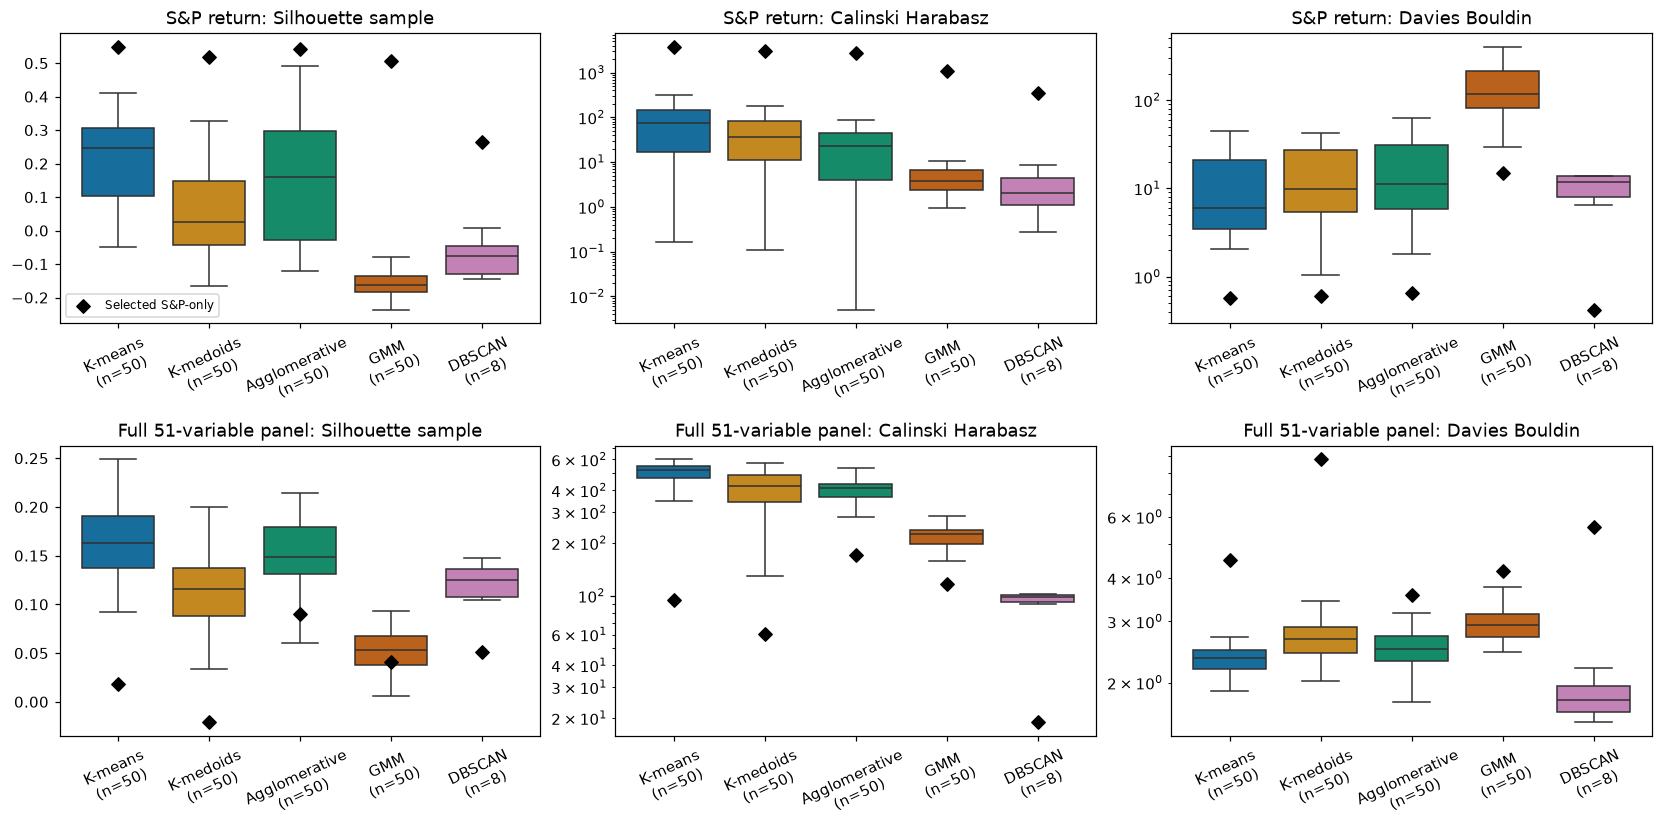

In [64]:
reference_rows = []
reference_spaces = {"S&P return": return_values, "Full 51-variable panel": profile_scaled_df.to_numpy()}
for space, values in reference_spaces.items():
    distances = squareform(pdist(values[score_indices]))
    for (name, repeat), labels in label_runs.items():
        scores = evaluate_clusters(labels, values, distances)
        reference_rows.append({"Model": name, "Repeat": repeat, "Source": "Randomized",
                               "Reference_space": space, **scores})
    for name, labels in benchmark_labels.items():
        scores = evaluate_clusters(labels, values, distances)
        reference_rows.append({"Model": name, "Repeat": 0, "Source": "S&P-only",
                               "Reference_space": space, **scores})

reference_scores = pd.DataFrame(reference_rows).drop(columns="Eligible")
reference_summary = reference_scores.groupby(["Reference_space", "Model", "Source"]).agg(
    Fits=("Repeat", "count"), Silhouette_median=("Silhouette_sample", "median"),
    Calinski_Harabasz_median=("Calinski_Harabasz", "median"),
    Davies_Bouldin_median=("Davies_Bouldin", "median"), Coverage_mean_pct=("Coverage_pct", "mean"),
)
display(reference_summary.round(4))

metrics = ["Silhouette_sample", "Calinski_Harabasz", "Davies_Bouldin"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), layout="constrained")
for i, space in enumerate(reference_spaces):
    randomized = reference_scores.loc[reference_scores["Reference_space"].eq(space)
                                      & reference_scores["Source"].eq("Randomized")]
    baseline = reference_scores.loc[reference_scores["Reference_space"].eq(space)
                                   & reference_scores["Source"].eq("S&P-only")].set_index("Model")
    for j, metric in enumerate(metrics):
        ax = axes[i, j]
        sns.boxplot(data=randomized, x="Model", y=metric, order=list(model_functions),
                    hue="Model", palette="colorblind", legend=False, showfliers=False, ax=ax)
        ax.scatter(np.arange(len(model_functions)), baseline.reindex(model_functions)[metric],
                   marker="D", color="black", s=38, zorder=5, label="Selected S&P-only")
        if metric in ["Calinski_Harabasz", "Davies_Bouldin"]:
            ax.set_yscale("log")
        ax.set(title=f"{space}: {metric.replace('_', ' ')}", xlabel="", ylabel="")
        counts = randomized.groupby("Model")[metric].count()
        ax.set_xticks(range(len(model_functions)),
                      [f"{name}\n(n={counts.get(name, 0)})" for name in model_functions], rotation=25)
        if i == j == 0:
            ax.legend(fontsize=8)
fig.savefig(BENCHMARK_DIR / "common_space_metrics.png", dpi=160)
plt.show()

### Mean and volatility profiles at matched cluster counts

Coloured boxes and faint points are randomized fits at each model's modal selected K. Black diamonds are S&P-only controls fitted at that same K, not necessarily the independently selected benchmark. Titles report the conditional randomized-run counts. Return ranks are ordered within each fit; rank correspondence is not membership matching. Both mean and volatility are daily log-return percentage units. The dashed lines are the full-sample unconditional values. An unavailable eligible control is labelled rather than forced.

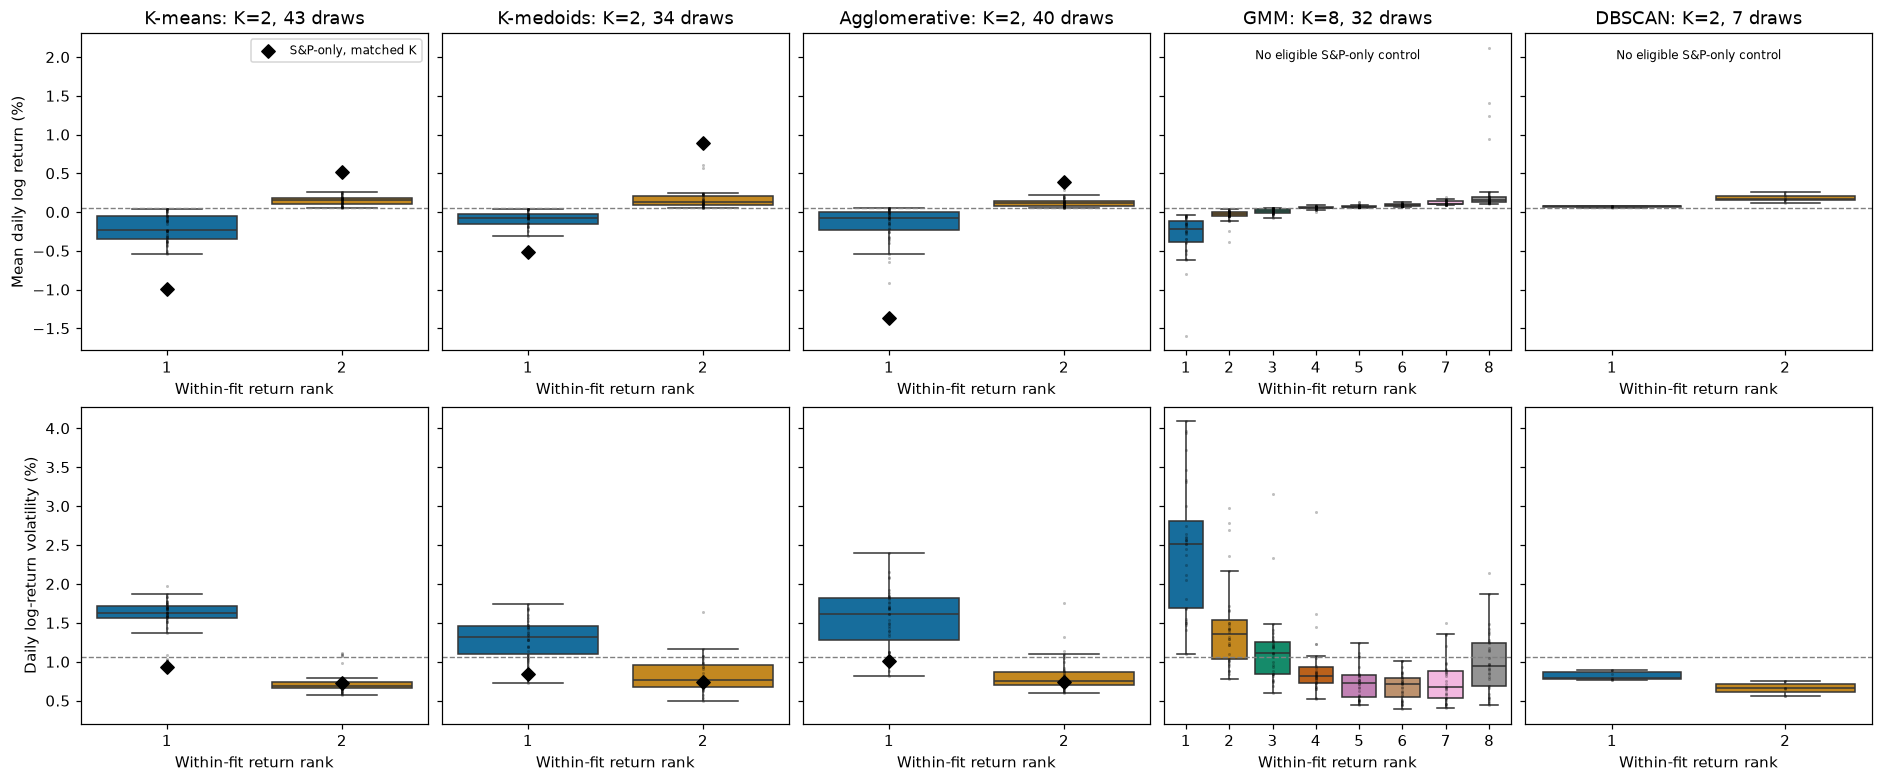

Draws  ...  SP_only_share_pct
Model         Clusters Return_rank         ...                   
Agglomerative 2        1               40  ...            19.4490
                       2               40  ...            80.5510
DBSCAN        2        1                7  ...                NaN
                       2                7  ...                NaN
GMM           8        1               32  ...                NaN
                       2               32  ...                NaN
                       3               32  ...                NaN
                       4               32  ...                NaN
                       5               32  ...                NaN
                       6               32  ...                NaN
                       7               32  ...                NaN
                       8               32  ...                NaN
K-means       2        1               43  ...            31.2121
                       2               43  ...            68.7879
K-medoids     2        1               34  ...            59.7521
                       2               34  ...            40.2479

[16 rows x 9 columns]

In [58]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7), sharey="row", layout="constrained")
for j, name in enumerate(model_functions):
    randomized = modal_equity_profiles.loc[modal_equity_profiles["Model"].eq(name)]
    baseline = control_profiles.loc[control_profiles["Model"].eq(name)].sort_values("Return_rank")
    for i, (metric, unconditional) in enumerate([
        ("Mean_log_pct", unconditional_mean_pct), ("Std_log_pct", unconditional_vol_pct)
    ]):
        ax = axes[i, j]
        if not randomized.empty:
            sns.boxplot(data=randomized, x="Return_rank", y=metric, hue="Return_rank",
                        palette="colorblind", legend=False, showfliers=False, ax=ax)
            sns.stripplot(data=randomized, x="Return_rank", y=metric, color="black",
                          jitter=False, size=2, alpha=0.25, ax=ax)
        if not baseline.empty:
            ax.scatter(baseline["Return_rank"] - 1, baseline[metric], marker="D", color="black",
                       s=38, zorder=5, label="S&P-only, matched K")
        ax.axhline(unconditional, color="grey", linestyle="--", linewidth=0.9)
        ax.set(xlabel="Within-fit return rank", ylabel="")
    k = modal_counts.get(name, np.nan)
    axes[0, j].set_title(f"{name}: K={k}, {randomized['Repeat'].nunique()} draws")
    if baseline.empty:
        axes[0, j].text(0.5, 0.95, "No eligible S&P-only control", ha="center", va="top",
                        transform=axes[0, j].transAxes, fontsize=8)
axes[0, 0].set_ylabel("Mean daily log return (%)")
axes[1, 0].set_ylabel("Daily log-return volatility (%)")
axes[0, 0].legend(fontsize=8)
fig.savefig(BENCHMARK_DIR / "matched_count_profiles.png", dpi=160)
plt.show()

control_profile_comparison = modal_equity_summary[["Draws", "Mean_return_median_pct",
    "Mean_return_p10_pct", "Mean_return_p90_pct", "Volatility_median_pct", "Cluster_share_median_pct"]].join(
    control_profiles.set_index(["Model", "Clusters", "Return_rank"])[[
        "Mean_log_pct", "Std_log_pct", "Share_all_dates_pct"]].rename(columns={
            "Mean_log_pct": "SP_only_mean_log_pct", "Std_log_pct": "SP_only_vol_pct",
            "Share_all_dates_pct": "SP_only_share_pct"}), how="left")
display(control_profile_comparison.round(4))

### Membership and profile agreement with the S&P-only partitions

ARI and AMI compare every eligible randomized fit with the independently selected benchmark, allowing different cluster counts. Profile differences require equal K and are matched by overlapping dates rather than return rank. A second comparison uses the explicit matched-K controls, retaining only randomized fits with that same count. Mean/volatility distances are RMS differences in daily log-return basis points. Tables report shared assigned coverage and the number of comparisons; DBSCAN noise never becomes an economic state.

Comparisons  ...  Worst_cluster_Jaccard_median
Model         Reference                        ...                              
Agglomerative Matched-K S&P-only           40  ...                        0.2325
              Selected S&P-only            50  ...                        0.2325
DBSCAN        Selected S&P-only             8  ...                           NaN
GMM           Selected S&P-only            50  ...                           NaN
K-means       Matched-K S&P-only           43  ...                        0.2846
              Selected S&P-only            50  ...                           NaN
K-medoids     Matched-K S&P-only           34  ...                        0.2723
              Selected S&P-only            50  ...                        0.0364

[8 rows x 9 columns]

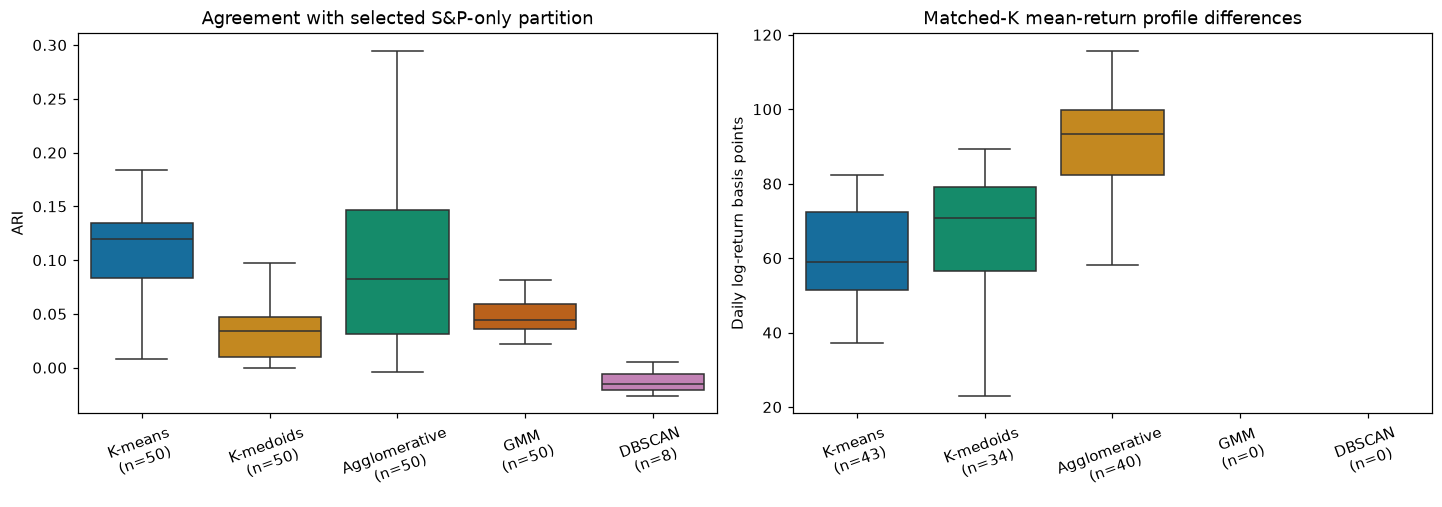

In [59]:
def compare_to_sp500(labels, baseline):
    common = (labels >= 0) & (baseline >= 0)
    ids = np.unique(labels[labels >= 0])
    baseline_ids = np.unique(baseline[baseline >= 0])
    row = {"Shared_assigned_pct": 100 * common.mean(), "Same_count": len(ids) == len(baseline_ids),
           "ARI": np.nan, "AMI": np.nan, "Mean_RMS_difference_bp": np.nan,
           "Vol_RMS_difference_bp": np.nan, "Worst_cluster_Jaccard": np.nan}
    if min(len(np.unique(labels[common])), len(np.unique(baseline[common]))) < 2:
        return row
    row.update(ARI=adjusted_rand_score(labels[common], baseline[common]),
               AMI=adjusted_mutual_info_score(labels[common], baseline[common]))
    if row["Same_count"]:
        overlap = np.zeros((len(ids), len(baseline_ids)), dtype=int)
        np.add.at(overlap, (np.searchsorted(ids, labels[common]), np.searchsorted(baseline_ids, baseline[common])), 1)
        a, b = linear_sum_assignment(-overlap)
        profile = sp500_profile(labels).set_index("Cluster").loc[ids]
        reference = sp500_profile(baseline).set_index("Cluster").loc[baseline_ids]
        mean_difference = profile["Mean"].to_numpy()[a] - reference["Mean"].to_numpy()[b]
        vol_difference = profile["Std"].to_numpy()[a] - reference["Std"].to_numpy()[b]
        intersection = overlap[a, b]
        union = profile["Count"].to_numpy()[a] + reference["Count"].to_numpy()[b] - intersection
        row.update(Mean_RMS_difference_bp=10000 * np.sqrt(np.mean(mean_difference ** 2)),
                   Vol_RMS_difference_bp=10000 * np.sqrt(np.mean(vol_difference ** 2)),
                   Worst_cluster_Jaccard=np.min(intersection / union))
    return row


agreement_rows = []
for (name, repeat), labels in label_runs.items():
    if name in benchmark_labels:
        agreement_rows.append({"Model": name, "Repeat": repeat, "Reference": "Selected S&P-only",
                               **compare_to_sp500(labels, benchmark_labels[name])})
    if name in control_labels and len(np.unique(labels[labels >= 0])) == int(modal_counts[name]):
        agreement_rows.append({"Model": name, "Repeat": repeat, "Reference": "Matched-K S&P-only",
                               **compare_to_sp500(labels, control_labels[name])})

benchmark_agreement = pd.DataFrame(agreement_rows)
benchmark_agreement_summary = benchmark_agreement.groupby(["Model", "Reference"]).agg(
    Comparisons=("Repeat", "count"), ARI_median=("ARI", "median"), AMI_median=("AMI", "median"),
    Shared_assigned_mean_pct=("Shared_assigned_pct", "mean"), Same_count_pct=("Same_count", lambda values: 100 * values.mean()),
    Matched_profile_comparisons=("Mean_RMS_difference_bp", "count"),
    Mean_RMS_median_bp=("Mean_RMS_difference_bp", "median"),
    Vol_RMS_median_bp=("Vol_RMS_difference_bp", "median"),
    Worst_cluster_Jaccard_median=("Worst_cluster_Jaccard", "median"),
)
display(benchmark_agreement_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, reference, metric, title in [
    (axes[0], "Selected S&P-only", "ARI", "Agreement with selected S&P-only partition"),
    (axes[1], "Matched-K S&P-only", "Mean_RMS_difference_bp", "Matched-K mean-return profile differences"),
]:
    values = benchmark_agreement.loc[benchmark_agreement["Reference"].eq(reference)]
    sns.boxplot(data=values, x="Model", y=metric, order=list(model_functions), hue="Model",
                palette="colorblind", legend=False, showfliers=False, ax=ax)
    counts = values.groupby("Model")[metric].count()
    ax.set_xticks(range(len(model_functions)), [f"{name}\n(n={counts.get(name, 0)})" for name in model_functions], rotation=20)
    ax.set(title=title, xlabel="", ylabel="ARI" if metric == "ARI" else "Daily log-return basis points")
fig.savefig(BENCHMARK_DIR / "agreement_with_benchmark.png", dpi=160)
plt.show()

### Counts, coverage and descriptive return separation

The randomized summaries below use all eligible draws. The benchmark is a single selected fit, so it has no feature-resampling spread. Return-mean R-squared describes the assigned-sample variance decomposition from the preceding section; it is neither a forecast score nor a measure of PCA variance retention. Direct clustering of returns is expected to emphasize their mean separation. Added contextual features may change the partitions toward volatility, macro or trend states; whether that helps EP still requires separate validation.
Return-only groups can be value bands or distribution components; the selected count does not by itself establish discrete economic regimes.


In [63]:
benchmark_separation_rows = []
for name, labels in benchmark_labels.items():
    profile = sp500_profile(labels)
    values = equity_returns.loc[labels >= 0]
    between_ss = (profile["Count"] * (profile["Mean"] - values.mean()) ** 2).sum()
    total_ss = ((values - values.mean()) ** 2).sum()
    benchmark_separation_rows.append({"Model": name,
        "Return_mean_R2_pct": 100 * between_ss / total_ss,
        "High_minus_low_bp": 10000 * (profile["Mean"].max() - profile["Mean"].min())})
benchmark_return_separation = pd.DataFrame(benchmark_separation_rows)

benchmark_overview = benchmark_results.set_index("Model")[[
    "Selected", "Clusters", "Coverage_pct", "Model_seconds", "Silhouette_sample",
    "Calinski_Harabasz", "Davies_Bouldin"]].join(benchmark_return_separation.set_index("Model"))
benchmark_overview = benchmark_overview.rename(columns={
    "Selected": "Eligible", "Clusters": "Selected_K", "Silhouette_sample": "Native_silhouette"})
randomized_overview = performance_summary[["Eligible_runs_pct", "Modal_clusters", "Modal_cluster_share_pct",
    "Coverage_mean_pct", "Search_seconds_mean", "Silhouette_median"]].join(
        return_separation.groupby("Model")[["Return_mean_R2_pct", "High_minus_low_bp"]].median())
display(benchmark_overview.round(4))
display(randomized_overview.round(4))
benchmark_comparison = pd.DataFrame({
    "SP_only_selected_K": benchmark_overview["Selected_K"],
    "Randomized_modal_K": randomized_overview["Modal_clusters"],
    "Randomized_modal_share_pct": randomized_overview["Modal_cluster_share_pct"],
    "SP_only_coverage_pct": benchmark_overview["Coverage_pct"],
    "Randomized_eligible_pct": randomized_overview["Eligible_runs_pct"],
    "SP_only_return_R2_pct": benchmark_overview["Return_mean_R2_pct"],
    "Randomized_return_R2_median_pct": randomized_overview["Return_mean_R2_pct"],
})
display(benchmark_comparison.round(4))


,Eligible,Selected_K,Coverage_pct,Model_seconds,Native_silhouette,Calinski_Harabasz,Davies_Bouldin,Return_mean_R2_pct,High_minus_low_bp
Model,,,,,,,,,
K-means,True,5,100.0000,0.6622,0.5497,3839.5800,0.5804,80.9043,659.5617
K-medoids,True,8,100.0000,7.0564,0.5190,3065.6552,0.5982,85.5591,542.9533
Agglomerative,True,2,100.0000,0.4036,0.5424,2719.3075,0.6601,42.8419,175.5796
GMM,True,4,100.0000,0.5469,0.5067,1105.2619,14.8336,47.7656,252.3549
DBSCAN,True,4,92.1488,0.2818,0.2646,355.6556,0.4201,24.2054,321.2043


,Eligible_runs_pct,Modal_clusters,Modal_cluster_share_pct,Coverage_mean_pct,Search_seconds_mean,Silhouette_median,Return_mean_R2_pct,High_minus_low_bp
Model,,,,,,,,
K-means,100.0,2,86.0,100.000,1.0614,0.2280,1.9978,37.8286
K-medoids,100.0,2,68.0,100.000,5.8052,0.1724,1.2571,25.2966
Agglomerative,100.0,2,80.0,100.000,0.4164,0.2081,0.8900,24.2379
GMM,100.0,8,64.0,100.000,2.0324,0.0705,0.6385,37.7822
DBSCAN,16.0,2,87.5,91.801,1.9271,0.2841,0.0607,11.7682


,SP_only_selected_K,Randomized_modal_K,Randomized_modal_share_pct,SP_only_coverage_pct,Randomized_eligible_pct,SP_only_return_R2_pct,Randomized_return_R2_median_pct
Model,,,,,,,
K-means,5,2,86.0,100.0000,100.0,80.9043,1.9978
K-medoids,8,2,68.0,100.0000,100.0,85.5591,1.2571
Agglomerative,2,2,80.0,100.0000,100.0,42.8419,0.8900
GMM,4,8,64.0,100.0000,100.0,47.7656,0.6385
DBSCAN,4,2,87.5,92.1488,16.0,24.2054,0.0607


In [61]:
for filename, table in {
    "selected_results": benchmark_results, "candidate_results": benchmark_candidates,
    "selected_profiles": benchmark_profiles, "control_results": control_results,
    "control_profiles": control_profiles, "common_reference_scores": reference_scores,
    "agreement_by_run": benchmark_agreement, "return_separation": benchmark_return_separation,
}.items():
    table.to_csv(BENCHMARK_DIR / f"{filename}.csv", index=False)
for filename, table in {
    "common_reference_summary": reference_summary, "profile_comparison": control_profile_comparison,
    "agreement_summary": benchmark_agreement_summary, "benchmark_overview": benchmark_overview,
    "randomized_overview": randomized_overview,
}.items():
    table.to_csv(BENCHMARK_DIR / f"{filename}.csv")
np.savez_compressed(BENCHMARK_DIR / "selected_labels.npz", **benchmark_labels)
np.savez_compressed(BENCHMARK_DIR / "control_labels.npz", **control_labels)
benchmark_settings = {
    "features": [FIXED_FEATURE], "dimensions": 1, "fit_repetitions": 1,
    "dates": len(X_complete), "model_seed": MODEL_SEED, "k_values": K_VALUES,
    "silhouette_rows": len(score_indices), "min_cluster_share": MIN_CLUSTER_SHARE,
    "minimum_cluster_rows": 20, "min_coverage_pct": MIN_COVERAGE,
    "profile_control_counts": modal_counts.to_dict(),
    "common_reference_spaces": list(reference_spaces),
    "comparison": "descriptive full-sample benchmark; no EP or forecasting performance claim",
}
(BENCHMARK_DIR / "settings.json").write_text(json.dumps(benchmark_settings, indent=2))
benchmark_comparison.to_csv(BENCHMARK_DIR / "comparison.csv")


Out[7]: 609


### Save results and finish with the comparison table

In [30]:
for filename, table in {
    "selected_results": results, "candidate_results": candidate_results,
    "feature_draws": feature_draws, "profile_means": profile_means,
    "profile_stds": profile_stds, "stability_pairs": stability_pairs,
}.items():
    table.to_csv(RESULTS_DIR / f"{filename}.csv", index=False)
for filename, table in {
    "performance_summary": performance_summary, "stability_summary": stability_summary,
    "cluster_frequencies": cluster_frequencies, "feature_usage": feature_usage,
    "family_usage": family_usage,
}.items():
    table.to_csv(RESULTS_DIR / f"{filename}.csv")
np.savez_compressed(RESULTS_DIR / "selected_labels.npz", **{
    f"{name}__{repeat}": labels for (name, repeat), labels in label_runs.items()})
np.savez_compressed(RESULTS_DIR / "coassignment.npz", **consensus_matrices)
np.savez_compressed(RESULTS_DIR / "coassignment_denominators.npz", **consensus_denominators)
pd.Series(X_complete.index, name="date").to_csv(RESULTS_DIR / "label_dates.csv", index=False)
pd.Series(consensus_dates, name="date").to_csv(RESULTS_DIR / "consensus_dates.csv", index=False)
pd.Series(X_complete.index[score_indices], name="date").to_csv(RESULTS_DIR / "silhouette_dates.csv", index=False)

run_settings = {
    "repetitions": N_REPEATS, "macro_per_draw": 5, "technical_per_draw": 5,
    "fixed_features": [FIXED_FEATURE], "total_inputs_per_draw": 11,
    "feature_seed": FEATURE_SEED, "model_seed": MODEL_SEED, "k_values": K_VALUES,
    "pca_variance": PCA_VARIANCE, "silhouette_rows": len(score_indices),
    "silhouette_seed": 123, "log_columns": log_columns,
    "min_cluster_share": MIN_CLUSTER_SHARE, "minimum_cluster_rows": 20,
    "min_coverage_pct": MIN_COVERAGE, "pair_limit_per_model": 1000, "pair_seed": 321,
    "rows": len(X_complete), "first_date": str(X_complete.index.min().date()),
    "last_date": str(X_complete.index.max().date()),
    "profile_scale": "fixed 50-feature selective-log/StandardScaler panel plus standardized S&P log return; descriptive full sample",
    "validation": "full-sample feature sensitivity, not out-of-sample economic performance",
}
(RESULTS_DIR / "settings.json").write_text(json.dumps(run_settings, indent=2))

comparison = performance_summary.join(stability_summary[[
    "ARI_median", "ARI_p10", "AMI_median", "Same_count_pct",
    "Profile_RMS_z_median", "Profile_std_RMS_z_median", "Worst_cluster_Jaccard_median",
]])
comparison.to_csv(RESULTS_DIR / "comparison.csv")
comparison.round(3)

Out[30]: 
               Eligible_runs  ...  Worst_cluster_Jaccard_median
Model                         ...                              
K-means                   50  ...                         0.513
K-medoids                 50  ...                         0.376
Agglomerative             50  ...                         0.302
GMM                       50  ...                         0.050
DBSCAN                     8  ...                         0.797

[5 rows x 19 columns]


## Interpretation and remaining checks

High count stability with low ARI would mean similar resolution but different date assignments. High ARI and low matched-profile distance would support robustness to this particular balanced feature lottery. Modest silhouettes would still indicate limited geometric separation; a stable but coarse stress split can underfit economically relevant distinctions. Different methods may select different counts because their objectives and selection rules differ.

The fit/search settings, screens and repeated sample silhouettes are part of the result. A method with fewer eligible draws has not established superior robustness by performing well only on its surviving subsets. A high modal count share does not prove the true number of regimes; K=1 was not tested by silhouette. Retain all candidates and avoid selecting only the most attractive repetitions.

This implementation covers balanced 5+5 feature sensitivity with a mandatory equity-return anchor, membership/profile comparisons and descriptive geometry. Unrestricted and family-stratified draws, alternative subset sizes, full-pool benchmarks, exact-silhouette checks, initialization checks, family ablations, surrogate/null controls and chronological EP/return validation remain separate experiments. None of the reported in-sample metrics demonstrates forecasting or portfolio performance.

Because S&P 500 log return is present in every fit, part of any agreement may come from that common anchor. The S&P-only benchmark above tests how the contextual partitions differ from direct return clustering; the no-anchor sensitivity remains a separate check. Including contemporaneous return in clustering also makes its within-cluster return profile descriptive; it does not establish predictability of subsequent returns.
